<a href="https://colab.research.google.com/github/keerthanavignakanthan/Vit_D_Deficiency_pred/blob/main/Vitamin_D_Deficiency_ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd

# Read the six NHANES datasets
vid = pd.read_sas('/content/VID_L.xpt.txt', format='xport')
demo = pd.read_sas('/content/DEMO_L.xpt.txt', format='xport')
bmx = pd.read_sas('/content/BMX_L.xpt.txt', format='xport')
paq = pd.read_sas('/content/PAQ_L.xpt.txt', format='xport')
diet = pd.read_sas('/content/DR1TOT_L.xpt.txt', format='xport')
rhq = pd.read_sas('/content/RHQ_L.xpt.txt', format='xport')

print("All six datasets loaded successfully!")

All six datasets loaded successfully!


In [7]:
# Check the number of rows and columns in each dataset

print("Vitamin D:", vid.shape)
print("Demographics:", demo.shape)
print("Body Measurements:", bmx.shape)
print("Physical Activity:", paq.shape)
print("Dietary Intake:", diet.shape)
print("Reproductive Health:", rhq.shape)

Vitamin D: (8727, 10)
Demographics: (11933, 27)
Body Measurements: (8860, 22)
Physical Activity: (8153, 8)
Dietary Intake: (8860, 168)
Reproductive Health: (3917, 13)


In [8]:
# Check whether SEQN contains duplicate IDs

datasets = {
    "Vitamin D": vid,
    "Demographics": demo,
    "Body Measurements": bmx,
    "Physical Activity": paq,
    "Dietary Intake": diet,
    "Reproductive Health": rhq
}

for name, df in datasets.items():
    print(name)
    print("Missing IDs:", df["SEQN"].isna().sum())
    print("Duplicate IDs:", df["SEQN"].duplicated().sum())
    print("-------------------------")

Vitamin D
Missing IDs: 0
Duplicate IDs: 0
-------------------------
Demographics
Missing IDs: 0
Duplicate IDs: 0
-------------------------
Body Measurements
Missing IDs: 0
Duplicate IDs: 0
-------------------------
Physical Activity
Missing IDs: 0
Duplicate IDs: 0
-------------------------
Dietary Intake
Missing IDs: 0
Duplicate IDs: 0
-------------------------
Reproductive Health
Missing IDs: 0
Duplicate IDs: 0
-------------------------


In [9]:
# Merge all six datasets using SEQN

merged = vid.merge(demo, on="SEQN", how="inner")
merged = merged.merge(bmx, on="SEQN", how="inner")
merged = merged.merge(paq, on="SEQN", how="inner")
merged = merged.merge(diet, on="SEQN", how="inner")
merged = merged.merge(rhq, on="SEQN", how="inner")

print("Merged dataset shape:", merged.shape)
print("Unique participants:", merged["SEQN"].nunique())

Merged dataset shape: (3479, 243)
Unique participants: 3479


In [10]:
# Filter female participants

women = merged[merged["RIAGENDR"] == 2].copy()

print("Total participants:", len(merged))
print("Female participants:", len(women))
print("Number of variables:", women.shape[1])

Total participants: 3479
Female participants: 3479
Number of variables: 243


In [11]:
print(merged["RIAGENDR"].value_counts(dropna=False))

RIAGENDR
2.0    3479
Name: count, dtype: int64


In [12]:
# Check participant counts after each merge

m1 = vid.merge(demo, on="SEQN", how="inner")
m2 = m1.merge(bmx, on="SEQN", how="inner")
m3 = m2.merge(paq, on="SEQN", how="inner")
m4 = m3.merge(diet, on="SEQN", how="inner")
m5 = m4.merge(rhq, on="SEQN", how="inner")

print("Vitamin D + Demographics:", len(m1))
print("After Body Measurements:", len(m2))
print("After Physical Activity:", len(m3))
print("After Dietary Intake:", len(m4))
print("After Reproductive Health:", len(m5))

Vitamin D + Demographics: 8727
After Body Measurements: 8727
After Physical Activity: 6337
After Dietary Intake: 6337
After Reproductive Health: 3479


In [13]:
# Check missing values in the merged dataset before adding RHQ

base = vid.merge(demo, on="SEQN", how="inner")
base = base.merge(bmx, on="SEQN", how="left")
base = base.merge(paq, on="SEQN", how="left")
base = base.merge(diet, on="SEQN", how="left")

print("Participants:", len(base))

print("\nMissing values by dataset:")
print("Body Measurements:", base["BMXBMI"].isna().sum())
print("Physical Activity:", base["PAD680"].isna().sum())
print("Dietary Intake:", base["DR1TKCAL"].isna().sum())

Participants: 8727

Missing values by dataset:
Body Measurements: 256
Physical Activity: 2396
Dietary Intake: 2087


In [14]:
# Examine Vitamin D measurements

print("Vitamin D measurement summary:")
print(base["LBXVIDMS"].describe())

print("\nMissing Vitamin D values:")
print(base["LBXVIDMS"].isna().sum())

Vitamin D measurement summary:
count    7307.000000
mean       77.458826
std        36.218293
min         7.970000
25%        53.000000
50%        72.000000
75%        95.650000
max       424.000000
Name: LBXVIDMS, dtype: float64

Missing Vitamin D values:
1420


In [15]:
# Keep participants with measured Vitamin D values

analysis_data = base.dropna(subset=["LBXVIDMS"]).copy()

# Create the target variable
analysis_data["VitaminD_Deficient"] = (
    analysis_data["LBXVIDMS"] < 50
).astype(int)

print("Participants with Vitamin D measurements:",
      len(analysis_data))

print("\nVitamin D classification:")
print(analysis_data["VitaminD_Deficient"].value_counts())

print("\nPercentage distribution:")
print(
    analysis_data["VitaminD_Deficient"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Participants with Vitamin D measurements: 7307

Vitamin D classification:
VitaminD_Deficient
0    5734
1    1573
Name: count, dtype: int64

Percentage distribution:
VitaminD_Deficient
0    78.47
1    21.53
Name: proportion, dtype: float64


In [16]:
# Filter women first
women_data = base[base["RIAGENDR"] == 2].copy()

# Remove participants with missing Vitamin D measurements
women_data = women_data.dropna(subset=["LBXVIDMS"]).copy()

# Create Vitamin D deficiency target
women_data["VitaminD_Deficient"] = (
    women_data["LBXVIDMS"] < 50
).astype(int)

print("Women with measured Vitamin D:", len(women_data))

print("\nVitamin D classification:")
print(women_data["VitaminD_Deficient"].value_counts())

print("\nPercentage distribution:")
print(
    women_data["VitaminD_Deficient"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Women with measured Vitamin D: 3927

Vitamin D classification:
VitaminD_Deficient
0    3128
1     799
Name: count, dtype: int64

Percentage distribution:
VitaminD_Deficient
0    79.65
1    20.35
Name: proportion, dtype: float64


In [17]:
# Add reproductive health data using a left join

women_full = women_data.merge(
    rhq,
    on="SEQN",
    how="left"
)

print("Total women:", len(women_full))
print("Women with reproductive health records:",
      women_full["RHQ010"].notna().sum())
print("Women without reproductive health records:",
      women_full["RHQ010"].isna().sum())

Total women: 3927
Women with reproductive health records: 3068
Women without reproductive health records: 859


In [18]:
# Check availability of all reproductive-health variables

rhq_columns = [col for col in rhq.columns if col != "SEQN"]

print("Reproductive-health variables:", len(rhq_columns))

print("\nMissing values in each variable:")
print(women_full[rhq_columns].isna().sum())

print("\nWomen with at least one reproductive-health response:",
      women_full[rhq_columns].notna().any(axis=1).sum())

Reproductive-health variables: 12

Missing values in each variable:
RHQ010     859
RHQ031     876
RHD043    2223
RHQ060    2218
RHQ078    2396
RHQ131    2493
RHD143    3401
RHD167    2883
RHQ200    3436
RHD280    1288
RHQ305    1291
RHQ332    3596
dtype: int64

Women with at least one reproductive-health response: 3071


In [19]:
# Display important predictor columns

selected_columns = [
    "RIDAGEYR",   # Age
    "BMXBMI",     # BMI
    "BMXWAIST",   # Waist circumference
    "PAD680",     # Sedentary activity
    "DR1TKCAL",   # Total calorie intake
    "DR1TVD",     # Dietary Vitamin D
    "LBXVIDMS"    # Measured Vitamin D
]

print(women_full[selected_columns].describe().round(2))

       RIDAGEYR   BMXBMI  BMXWAIST   PAD680  DR1TKCAL   DR1TVD  LBXVIDMS
count   3927.00  3856.00   3720.00  3180.00   3089.00  3089.00   3927.00
mean      44.39    28.48     93.43   428.81   1735.74     3.99     81.37
std       23.05     8.31     19.83   834.88    736.48     4.46     38.92
min        1.00    12.70     40.30     0.00      0.00     0.00      9.13
25%       24.00    22.70     80.00   180.00   1247.00     1.10     54.05
50%       46.00    27.20     92.20   300.00   1651.00     2.80     75.70
75%       65.00    33.30    106.70   480.00   2117.00     5.30    102.00
max       80.00    74.80    177.20  9999.00   7874.00    71.90    424.00


In [20]:
# Examine participant age distribution

print("Minimum age:", women_full["RIDAGEYR"].min())
print("Maximum age:", women_full["RIDAGEYR"].max())

print("\nAge group distribution:")

age_groups = pd.cut(
    women_full["RIDAGEYR"],
    bins=[0, 19, 29, 39, 49, 59, 69, 80],
    labels=["1-19", "20-29", "30-39", "40-49",
            "50-59", "60-69", "70-80"]
)

print(age_groups.value_counts().sort_index())

Minimum age: 1.0
Maximum age: 80.0

Age group distribution:
RIDAGEYR
1-19     857
20-29    326
30-39    469
40-49    424
50-59    483
60-69    756
70-80    612
Name: count, dtype: int64


In [21]:
# Select adult women aged 20 and above

adult_data = women_full[
    (women_full["RIDAGEYR"] >= 20) &
    (women_full["LBXVIDMS"].notna())
].copy()

# Create Vitamin D deficiency target
adult_data["VitaminD_Deficient"] = (
    adult_data["LBXVIDMS"] < 50
).astype(int)

print("Adult women:", len(adult_data))

print("\nVitamin D classification:")
print(adult_data["VitaminD_Deficient"].value_counts())

print("\nPercentage distribution:")
print(
    adult_data["VitaminD_Deficient"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Adult women: 3070

Vitamin D classification:
VitaminD_Deficient
0    2540
1     530
Name: count, dtype: int64

Percentage distribution:
VitaminD_Deficient
0    82.74
1    17.26
Name: proportion, dtype: float64


In [22]:
# Check missing values in adult women's dataset

print("Missing values in each variable:\n")

missing = adult_data.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (
        missing / len(adult_data) * 100
    ).round(2)
})

print(
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ].sort_values(
        by="Missing_Percentage",
        ascending=False
    )
)

Missing values in each variable:

          Missing_Count  Missing_Percentage
RIDEXAGM           3070              100.00
RIDAGEMN           3070              100.00
DMDHRGND           3070              100.00
DMDHRAGZ           3070              100.00
BMXHEAD            3070              100.00
...                 ...                 ...
LBDVE3LC             45                1.47
BMXBMI               42                1.37
BMXWT                37                1.21
BMXHT                31                1.01
PAD790Q               1                0.03

[212 rows x 2 columns]


In [23]:
# Variables relevant to our research

research_columns = [
    "RIDAGEYR",   # Age
    "BMXBMI",     # BMI
    "BMXWAIST",   # Waist circumference
    "PAD680",     # Sedentary activity
    "PAD790Q",    # Moderate activity frequency
    "PAD810Q",    # Vigorous activity frequency
    "DR1TKCAL",   # Daily calorie intake
    "DR1TVD",     # Dietary Vitamin D
    "RHQ010",     # Age at first menstrual period
    "RHQ031",     # Regular periods
    "RHQ131",     # Ever pregnant
    "LBXVIDMS"    # Measured Vitamin D (target source)
]

research_missing = pd.DataFrame({
    "Missing_Count": adult_data[research_columns].isna().sum(),
    "Missing_Percentage": (
        adult_data[research_columns].isna().mean() * 100
    ).round(2)
})

print(research_missing.sort_values(
    "Missing_Percentage",
    ascending=False
))

          Missing_Count  Missing_Percentage
RHQ131             1636               53.29
DR1TVD              588               19.15
DR1TKCAL            588               19.15
RHQ031              423               13.78
RHQ010              420               13.68
BMXWAIST            155                5.05
BMXBMI               42                1.37
PAD790Q               1                0.03
PAD680                0                0.00
RIDAGEYR              0                0.00
PAD810Q               0                0.00
LBXVIDMS              0                0.00


In [24]:
# Inspect physical activity responses

activity_columns = [
    "PAD680",
    "PAD790Q",
    "PAD810Q"
]

for col in activity_columns:
    print("\n", col)
    print(adult_data[col].value_counts(dropna=False).sort_index().tail(15))


 PAD680
PAD680
600.0     265
660.0      23
720.0     156
780.0      19
840.0      38
900.0      19
960.0      15
1020.0      3
1080.0      6
1140.0      1
1200.0      4
1260.0      1
1380.0      1
7777.0      1
9999.0     22
Name: count, dtype: int64

 PAD790Q
PAD790Q
7.0       201
8.0         5
10.0       11
12.0        4
14.0        1
15.0        7
20.0        5
21.0        1
22.0        1
24.0        1
29.0        1
30.0        1
7777.0      2
9999.0     14
NaN         1
Name: count, dtype: int64

 PAD810Q
PAD810Q
5.397605e-79    1829
1.000000e+00     425
2.000000e+00     366
3.000000e+00     231
4.000000e+00      93
5.000000e+00      60
6.000000e+00      21
7.000000e+00      25
8.000000e+00       2
9.000000e+00       1
1.000000e+01       3
2.000000e+01       1
2.300000e+01       1
2.400000e+01       1
9.999000e+03      11
Name: count, dtype: int64


In [25]:
!pip install pyreadstat

import pyreadstat

paq_check, metadata = pyreadstat.read_xport(
    "/content/PAQ_L.xpt.txt"
)

print(paq_check["PAD810Q"].value_counts(dropna=False).sort_index())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 13.0 MB/s  0:00:00
PAD810Q
0.0       4413
1.0       1286
2.0       1054
3.0        641
4.0        294
5.0        209
6.0         83
7.0         87
8.0          4
9.0          2
10.0         9
12.0         1
15.0         4
20.0         2
22.0         1
23.0         1
24.0         2
30.0         2
31.0         1
84.0         1
90.0         1
200.0        1
7777.0       4
9999.0      36
NaN         14
Name: count, dtype: int64


In [26]:
# Check special missing-value codes in PAQ data

print("7777 values in each column:")
print((paq_check == 7777).sum())

print("\n9999 values in each column:")
print((paq_check == 9999).sum())

7777 values in each column:
SEQN        0
PAD790Q    10
PAD790U     0
PAD800      0
PAD810Q     4
PAD810U     0
PAD820      1
PAD680      6
dtype: int64

9999 values in each column:
SEQN        0
PAD790Q    39
PAD790U     0
PAD800     19
PAD810Q    36
PAD810U     0
PAD820     13
PAD680     67
dtype: int64


In [27]:
import numpy as np

# Create a cleaned copy
paq_clean = paq_check.copy()

# Replace special missing-value codes with NaN
paq_clean = paq_clean.replace([7777, 9999], np.nan)

# Check the result
print("Remaining 7777 values:")
print((paq_clean == 7777).sum().sum())

print("\nRemaining 9999 values:")
print((paq_clean == 9999).sum().sum())

print("\nMissing values after cleaning:")
print(paq_clean.isna().sum())

Remaining 7777 values:
0

Remaining 9999 values:
0

Missing values after cleaning:
SEQN          0
PAD790Q      67
PAD790U       0
PAD800     1782
PAD810Q      54
PAD810U       0
PAD820     4480
PAD680       88
dtype: int64


In [28]:
# Replace original PAQ data with cleaned PAQ data
paq = paq_clean.copy()

# Rebuild the dataset
base = vid.merge(demo, on="SEQN", how="inner")
base = base.merge(bmx, on="SEQN", how="left")
base = base.merge(paq, on="SEQN", how="left")
base = base.merge(diet, on="SEQN", how="left")

# Filter female participants
women_data = base[base["RIAGENDR"] == 2].copy()

print("Total participants:", len(base))
print("Female participants:", len(women_data))
print("Missing physical activity values:")
print(women_data[["PAD790Q", "PAD800", "PAD810Q", "PAD820", "PAD680"]].isna().sum())

Total participants: 8727
Female participants: 4673
Missing physical activity values:
PAD790Q    1216
PAD800     1965
PAD810Q    1207
PAD820     3271
PAD680     1220
dtype: int64


In [29]:
# Check Vitamin D availability among women

print("Total women:", len(women_data))

print("Women with measured Vitamin D:",
      women_data["LBXVIDMS"].notna().sum())

print("Women without measured Vitamin D:",
      women_data["LBXVIDMS"].isna().sum())

print("\nVitamin D measurement summary:")
print(women_data["LBXVIDMS"].describe())

Total women: 4673
Women with measured Vitamin D: 3927
Women without measured Vitamin D: 746

Vitamin D measurement summary:
count    3927.000000
mean       81.369768
std        38.923789
min         9.130000
25%        54.050000
50%        75.700000
75%       102.000000
max       424.000000
Name: LBXVIDMS, dtype: float64


In [30]:
# Check missing values in adult women's modelling variables

research_columns = [
    "RIDAGEYR",
    "BMXBMI",
    "BMXWAIST",
    "PAD680",
    "DR1TKCAL",
    "DR1TVD",
    "LBXVIDMS",
    "VitaminD_Deficient"
]

print(adult_data[research_columns].isnull().sum())

print("\nDataset shape:")
print(adult_data[research_columns].shape)

RIDAGEYR                0
BMXBMI                 42
BMXWAIST              155
PAD680                  0
DR1TKCAL              588
DR1TVD                588
LBXVIDMS                0
VitaminD_Deficient      0
dtype: int64

Dataset shape:
(3070, 8)


In [31]:
# Check missingness in dietary variables

print("Both dietary variables missing:")
print(
    (adult_data["DR1TKCAL"].isna() &
     adult_data["DR1TVD"].isna()).sum()
)

print("\nOnly calorie intake missing:")
print(
    (adult_data["DR1TKCAL"].isna() &
     adult_data["DR1TVD"].notna()).sum()
)

print("\nOnly dietary Vitamin D missing:")
print(
    (adult_data["DR1TKCAL"].notna() &
     adult_data["DR1TVD"].isna()).sum()
)

Both dietary variables missing:
588

Only calorie intake missing:
0

Only dietary Vitamin D missing:
0


In [32]:
# Check dietary recall status

print("Is DR1DRSTZ available?")
print("DR1DRSTZ" in diet.columns)

if "DR1DRSTZ" in diet.columns:
    print("\nDietary recall status:")
    print(diet["DR1DRSTZ"].value_counts(dropna=False))

Is DR1DRSTZ available?
True

Dietary recall status:
DR1DRSTZ
1.0    6694
5.0    2063
4.0      60
2.0      43
Name: count, dtype: int64


In [33]:
# Compare dietary recall status with missing dietary intake

print(pd.crosstab(
    adult_data["DR1DRSTZ"],
    adult_data["DR1TKCAL"].isna(),
    margins=True
))

DR1TKCAL  False  True   All
DR1DRSTZ                   
1.0        2482     0  2482
2.0           0    12    12
5.0           0   576   576
All        2482   588  3070


In [34]:
# Select primary modelling variables

primary_columns = [
    "RIDAGEYR",
    "BMXBMI",
    "BMXWAIST",
    "PAD680",
    "LBXVIDMS",
    "VitaminD_Deficient"
]

primary_data = adult_data[primary_columns].copy()

print("Primary dataset shape:", primary_data.shape)

print("\nMissing values:")
print(primary_data.isna().sum())

Primary dataset shape: (3070, 6)

Missing values:
RIDAGEYR                0
BMXBMI                 42
BMXWAIST              155
PAD680                  0
LBXVIDMS                0
VitaminD_Deficient      0
dtype: int64


In [35]:
# Replace NHANES special missing codes in PAQ
paq = paq.replace([7777, 9999], np.nan)

# Check the cleaned values
print("Remaining 7777:", (paq == 7777).sum().sum())
print("Remaining 9999:", (paq == 9999).sum().sum())

print("\nMissing values in physical activity variables:")
print(paq[["PAD790Q", "PAD800", "PAD810Q", "PAD820", "PAD680"]].isna().sum())

Remaining 7777: 0
Remaining 9999: 0

Missing values in physical activity variables:
PAD790Q      67
PAD800     1782
PAD810Q      54
PAD820     4480
PAD680       88
dtype: int64


In [36]:
# Rebuild dataset using cleaned PAQ data
base = vid.merge(demo, on="SEQN", how="inner")
base = base.merge(bmx, on="SEQN", how="left")
base = base.merge(paq, on="SEQN", how="left")
base = base.merge(diet, on="SEQN", how="left")

# Keep female participants
women_data = base[base["RIAGENDR"] == 2].copy()

print("Total participants:", len(base))
print("Female participants:", len(women_data))
print("\nPhysical activity missing values:")
print(women_data[["PAD790Q", "PAD800", "PAD810Q", "PAD820", "PAD680"]].isna().sum())

Total participants: 8727
Female participants: 4673

Physical activity missing values:
PAD790Q    1216
PAD800     1965
PAD810Q    1207
PAD820     3271
PAD680     1220
dtype: int64


In [37]:
# Check special missing codes in dietary data

print("7777 values:")
print((diet == 7777).sum())

print("\n9999 values:")
print((diet == 9999).sum())

print("\nDietary recall status:")
print(diet["DR1DRSTZ"].value_counts(dropna=False))

7777 values:
SEQN        0
WTDRD1      0
WTDR2D      0
DR1DRSTZ    0
DR1EXMER    0
           ..
DRD370T     0
DRD370TQ    0
DRD370U     0
DRD370UQ    0
DRD370V     0
Length: 168, dtype: int64

9999 values:
SEQN        0
WTDRD1      0
WTDR2D      0
DR1DRSTZ    0
DR1EXMER    0
           ..
DRD370T     0
DRD370TQ    0
DRD370U     0
DRD370UQ    0
DRD370V     0
Length: 168, dtype: int64

Dietary recall status:
DR1DRSTZ
1.0    6694
5.0    2063
4.0      60
2.0      43
Name: count, dtype: int64


In [38]:
# Check dietary recall status in the adult-women dataset

print("Dietary recall status:")
print(adult_data["DR1DRSTZ"].value_counts(dropna=False))

print("\nDietary recall status vs missing calorie intake:")
print(pd.crosstab(
    adult_data["DR1DRSTZ"],
    adult_data["DR1TKCAL"].isna(),
    margins=True
))

Dietary recall status:
DR1DRSTZ
1.0    2482
5.0     576
2.0      12
Name: count, dtype: int64

Dietary recall status vs missing calorie intake:
DR1TKCAL  False  True   All
DR1DRSTZ                   
1.0        2482     0  2482
2.0           0    12    12
5.0           0   576   576
All        2482   588  3070


In [40]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [41]:
# Select women with reliable dietary recalls
dietary_data = adult_data[
    adult_data["DR1DRSTZ"] == 1
].copy()

print("Reliable dietary recall participants:", len(dietary_data))

print("\nMissing dietary values:")
print(dietary_data[["DR1TKCAL", "DR1TVD"]].isna().sum())

Reliable dietary recall participants: 2482

Missing dietary values:
DR1TKCAL    0
DR1TVD      0
dtype: int64


In [42]:
print("Vitamin D threshold used:", 50, "nmol/L")

print("\nVitamin D deficiency distribution:")
print(adult_data["VitaminD_Deficient"].value_counts())

print("\nPercentage distribution:")
print(
    adult_data["VitaminD_Deficient"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Vitamin D threshold used: 50 nmol/L

Vitamin D deficiency distribution:
VitaminD_Deficient
0    2540
1     530
Name: count, dtype: int64

Percentage distribution:
VitaminD_Deficient
0    82.74
1    17.26
Name: proportion, dtype: float64


In [43]:
# Select predictors and target

feature_columns = [
    "RIDAGEYR",
    "BMXBMI",
    "BMXWAIST",
    "PAD680"
]

X = adult_data[feature_columns].copy()
y = adult_data["VitaminD_Deficient"].copy()

print("Predictor dataset shape:", X.shape)
print("\nMissing values:")
print(X.isna().sum())

print("\nTarget dataset shape:", y.shape)

Predictor dataset shape: (3070, 4)

Missing values:
RIDAGEYR      0
BMXBMI       42
BMXWAIST    155
PAD680        0
dtype: int64

Target dataset shape: (3070,)


In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 2456
Testing samples: 614

Training target distribution:
VitaminD_Deficient
0    2032
1     424
Name: count, dtype: int64

Testing target distribution:
VitaminD_Deficient
0    508
1    106
Name: count, dtype: int64


In [45]:
from sklearn.impute import SimpleImputer

# Create median imputer
imputer = SimpleImputer(strategy="median")

# Learn medians from training data and transform both sets
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Convert back to DataFrames
X_train_imputed = pd.DataFrame(
    X_train_imputed,
    columns=feature_columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    X_test_imputed,
    columns=feature_columns,
    index=X_test.index
)

print("Missing values in training data:")
print(X_train_imputed.isna().sum())

print("\nMissing values in testing data:")
print(X_test_imputed.isna().sum())

Missing values in training data:
RIDAGEYR    0
BMXBMI      0
BMXWAIST    0
PAD680      0
dtype: int64

Missing values in testing data:
RIDAGEYR    0
BMXBMI      0
BMXWAIST    0
PAD680      0
dtype: int64


In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}

for name, model in models.items():

    model.fit(X_train_imputed, y_train)

    y_pred = model.predict(X_test_imputed)
    y_prob = model.predict_proba(X_test_imputed)[:, 1]

    print("\n", name)
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
    print("Precision:", round(precision_score(y_test, y_pred), 3))
    print("Recall:", round(recall_score(y_test, y_pred), 3))
    print("F1-score:", round(f1_score(y_test, y_pred), 3))
    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))
    print("PR-AUC:", round(average_precision_score(y_test, y_prob), 3))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


 Logistic Regression
Accuracy: 0.606
Precision: 0.242
Recall: 0.604
F1-score: 0.346
ROC-AUC: 0.644
PR-AUC: 0.311
Confusion Matrix:
 [[308 200]
 [ 42  64]]

 Random Forest
Accuracy: 0.814
Precision: 0.346
Recall: 0.085
F1-score: 0.136
ROC-AUC: 0.655
PR-AUC: 0.264
Confusion Matrix:
 [[491  17]
 [ 97   9]]


In [47]:
import pandas as pd
import numpy as np

# Clean special missing-value codes in physical activity data
paq_clean = paq.copy()
paq_clean = paq_clean.replace([7777, 9999], np.nan)

# Merge datasets using participant ID (SEQN)
base_clean = vid.merge(demo, on="SEQN", how="inner")

base_clean = base_clean.merge(
    bmx, on="SEQN", how="left"
)

base_clean = base_clean.merge(
    paq_clean, on="SEQN", how="left"
)

base_clean = base_clean.merge(
    diet, on="SEQN", how="left"
)

base_clean = base_clean.merge(
    rhq, on="SEQN", how="left"
)

# Select women aged 20 and above
adult_data_clean = base_clean[
    (base_clean["RIAGENDR"] == 2) &
    (base_clean["RIDAGEYR"] >= 20) &
    (base_clean["LBXVIDMS"].notna())
].copy()

# Define Vitamin D deficiency: below 50 nmol/L
adult_data_clean["VitaminD_Deficient"] = (
    adult_data_clean["LBXVIDMS"] < 50
).astype(int)

print("Adult women with measured Vitamin D:",
      len(adult_data_clean))

print("\nDeficiency distribution:")
print(adult_data_clean["VitaminD_Deficient"].value_counts())

print("\nPercentage distribution:")
print(
    adult_data_clean["VitaminD_Deficient"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDataset shape:", adult_data_clean.shape)

Adult women with measured Vitamin D: 3070

Deficiency distribution:
VitaminD_Deficient
0    2540
1     530
Name: count, dtype: int64

Percentage distribution:
VitaminD_Deficient
0    82.74
1    17.26
Name: proportion, dtype: float64

Dataset shape: (3070, 244)


In [48]:
# Validate the cleaned modelling dataset

print("Dataset shape:", adult_data_clean.shape)

print("\nSpecial codes in PAD680:")
print(
    adult_data_clean["PAD680"]
    .isin([7777, 9999])
    .sum()
)

print("\nMissing values in predictors:")
print(
    adult_data_clean[
        ["RIDAGEYR", "BMXBMI", "BMXWAIST", "PAD680"]
    ].isna().sum()
)

print("\nVitamin D target distribution:")
print(adult_data_clean["VitaminD_Deficient"].value_counts())

print("\nSedentary activity summary:")
print(adult_data_clean["PAD680"].describe())

Dataset shape: (3070, 244)

Special codes in PAD680:
0

Missing values in predictors:
RIDAGEYR      0
BMXBMI       42
BMXWAIST    155
PAD680       23
dtype: int64

Vitamin D target distribution:
VitaminD_Deficient
0    2540
1     530
Name: count, dtype: int64

Sedentary activity summary:
count    3047.000000
mean      359.949130
std       205.253245
min         0.000000
25%       180.000000
50%       300.000000
75%       480.000000
max      1380.000000
Name: PAD680, dtype: float64


In [49]:
# Select predictors and target from the cleaned dataset

feature_columns = [
    "RIDAGEYR",
    "BMXBMI",
    "BMXWAIST",
    "PAD680"
]

X = adult_data_clean[feature_columns].copy()
y = adult_data_clean["VitaminD_Deficient"].copy()

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values:")
print(X.isnull().sum())

print("\nTarget distribution:")
print(y.value_counts())

Predictor shape: (3070, 4)
Target shape: (3070,)

Missing values:
RIDAGEYR      0
BMXBMI       42
BMXWAIST    155
PAD680       23
dtype: int64

Target distribution:
VitaminD_Deficient
0    2540
1     530
Name: count, dtype: int64


In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 2456
Testing samples: 614

Training target distribution:
VitaminD_Deficient
0    2032
1     424
Name: count, dtype: int64

Testing target distribution:
VitaminD_Deficient
0    508
1    106
Name: count, dtype: int64


In [51]:
from sklearn.impute import SimpleImputer

# Create median imputer
imputer = SimpleImputer(strategy="median")

# Fit only on training data
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Apply the same imputer to testing data
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing values in training data:")
print(X_train_imputed.isnull().sum())

print("\nMissing values in testing data:")
print(X_test_imputed.isnull().sum())

print("\nTraining shape:", X_train_imputed.shape)
print("Testing shape:", X_test_imputed.shape)

Missing values in training data:
RIDAGEYR    0
BMXBMI      0
BMXWAIST    0
PAD680      0
dtype: int64

Missing values in testing data:
RIDAGEYR    0
BMXBMI      0
BMXWAIST    0
PAD680      0
dtype: int64

Training shape: (2456, 4)
Testing shape: (614, 4)


In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}

results = {}

for name, model in models.items():

    model.fit(X_train_imputed, y_train)

    y_pred = model.predict(X_test_imputed)
    y_prob = model.predict_proba(X_test_imputed)[:, 1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    }

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

print("\nMODEL COMPARISON")
results_df = pd.DataFrame(results).T
print(results_df.round(4))


Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.60      0.71       508
           1       0.23      0.58      0.33       106

    accuracy                           0.59       614
   macro avg       0.55      0.59      0.52       614
weighted avg       0.76      0.59      0.64       614

Confusion Matrix:
[[303 205]
 [ 44  62]]

Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.97      0.90       508
           1       0.35      0.08      0.14       106

    accuracy                           0.81       614
   macro avg       0.59      0.53      0.52       614
weighted avg       0.75      0.81      0.76       614

Confusion Matrix:
[[491  17]
 [ 97   9]]

MODEL COMPARISON
                     Accuracy  Precision  Recall  F1-score  ROC-AUC  PR-AUC
Logistic Regression    0.5945     0.2322  0.5849    0.3324   0.6430  0.2993
Random For

In [53]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

lr_model.fit(X_train_imputed, y_train)

lr_pred = lr_model.predict(X_test_imputed)
lr_prob = lr_model.predict_proba(X_test_imputed)[:, 1]

print("LOGISTIC REGRESSION - STANDARDISED")

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

LOGISTIC REGRESSION - STANDARDISED

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.60      0.71       508
           1       0.23      0.58      0.33       106

    accuracy                           0.59       614
   macro avg       0.55      0.59      0.52       614
weighted avg       0.76      0.59      0.64       614


Confusion Matrix:
[[303 205]
 [ 44  62]]


In [54]:
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve

# Create Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Generate cross-validated probabilities on training data
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_prob = cross_val_predict(
    lr_pipeline,
    X_train_imputed,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Find threshold with the best F1-score
precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best threshold:", round(best_threshold, 4))
print("Cross-validation precision:", round(precision[best_index], 4))
print("Cross-validation recall:", round(recall[best_index], 4))
print("Cross-validation F1-score:", round(f1_scores[best_index], 4))

Best threshold: 0.4599
Cross-validation precision: 0.2847
Cross-validation recall: 0.7547
Cross-validation F1-score: 0.4134


In [55]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    average_precision_score
)

# Train on the complete training dataset
lr_pipeline.fit(X_train_imputed, y_train)

# Predict probabilities on unseen test data
test_prob = lr_pipeline.predict_proba(X_test_imputed)[:, 1]

# Apply the selected threshold
test_pred = (test_prob >= best_threshold).astype(int)

print("LOGISTIC REGRESSION - OPTIMISED THRESHOLD")
print("Threshold:", round(best_threshold, 4))

print("\nClassification Report:")
print(classification_report(y_test, test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nAdditional Metrics:")
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_prob), 4))

LOGISTIC REGRESSION - OPTIMISED THRESHOLD
Threshold: 0.4599

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.54      0.67       508
           1       0.23      0.65      0.34       106

    accuracy                           0.56       614
   macro avg       0.56      0.60      0.51       614
weighted avg       0.77      0.56      0.61       614


Confusion Matrix:
[[276 232]
 [ 37  69]]

Additional Metrics:
Accuracy: 0.5619
ROC-AUC: 0.6429
PR-AUC: 0.2993


In [56]:
# ============================================================
# FEATURE AUDIT (training rows only - test set not touched)
# ============================================================
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

train_df = adult_data_clean.loc[X_train.index].copy()
rhq_cols = [c for c in rhq.columns if c != "SEQN"]

candidates = {
    "Demographic":    ["RIDRETH3", "INDFMPIR", "DMDEDUC2", "DMDMARTZ",
                       "DMDBORN4", "RIDEXMON"],
    "Anthropometric": ["BMXBMI", "BMXWAIST", "BMXWT", "BMXHT"],
    "Activity":       ["PAD680", "PAD790Q", "PAD800", "PAD810Q", "PAD820"],
    "Diet":           ["DR1TKCAL", "DR1TVD", "DR1TCALC"],
    "Reproductive":   rhq_cols,
}

special_codes = [7, 9, 77, 99, 777, 999, 7777, 9999]

rows = []
for group, cols in candidates.items():
    for col in cols:
        if col not in train_df.columns:
            rows.append([group, col, "NOT FOUND", None, None, None, None])
            continue
        s = train_df[[col, "VitaminD_Deficient"]].dropna()
        miss_pct = round(train_df[col].isna().mean() * 100, 1)
        n_unique = train_df[col].nunique()
        n_special = int(train_df[col].isin(special_codes).sum())
        if s[col].nunique() > 1 and s["VitaminD_Deficient"].nunique() > 1:
            auc = roc_auc_score(s["VitaminD_Deficient"], s[col])
            strength = round(max(auc, 1 - auc), 3)
        else:
            strength = None
        rows.append([group, col, miss_pct, n_unique, n_special, strength, len(s)])

audit = pd.DataFrame(rows, columns=["Group", "Variable", "Missing_%",
                                    "N_unique", "Possible_special_codes",
                                    "Univariate_AUC", "N_used"])
print(audit.to_string(index=False))

# Nominal / seasonal variables: compare deficiency prevalence by category
for col in ["RIDRETH3", "RIDEXMON", "DMDEDUC2"]:
    if col in train_df.columns:
        print(f"\nDeficiency prevalence by {col} (training rows):")
        print(train_df.groupby(col)["VitaminD_Deficient"]
              .agg(n="size", prevalence="mean").round(3))

         Group Variable  Missing_%  N_unique  Possible_special_codes  Univariate_AUC  N_used
   Demographic RIDRETH3        0.0         6                     147           0.536    2456
   Demographic INDFMPIR       13.1       417                       0           0.612    2134
   Demographic DMDEDUC2        0.0         5                       0           0.595    2456
   Demographic DMDMARTZ        0.0         4                       1           0.580    2456
   Demographic DMDBORN4        0.0         2                       0           0.529    2456
   Demographic RIDEXMON        0.0         2                       0           0.588    2456
Anthropometric   BMXBMI        1.3       358                       0           0.584    2423
Anthropometric BMXWAIST        5.2       664                      16           0.554    2329
Anthropometric    BMXWT        1.1       772                       4           0.580    2428
Anthropometric    BMXHT        0.9       341                       0  

In [57]:
# ============================================================
# FEATURE AUDIT (training rows only - test set not touched)
# ============================================================
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

train_df = adult_data_clean.loc[X_train.index].copy()
rhq_cols = [c for c in rhq.columns if c != "SEQN"]

candidates = {
    "Demographic":    ["RIDRETH3", "INDFMPIR", "DMDEDUC2", "DMDMARTZ",
                       "DMDBORN4", "RIDEXMON"],
    "Anthropometric": ["BMXBMI", "BMXWAIST", "BMXWT", "BMXHT"],
    "Activity":       ["PAD680", "PAD790Q", "PAD800", "PAD810Q", "PAD820"],
    "Diet":           ["DR1TKCAL", "DR1TVD", "DR1TCALC"],
    "Reproductive":   rhq_cols,
}

special_codes = [7, 9, 77, 99, 777, 999, 7777, 9999]

rows = []
for group, cols in candidates.items():
    for col in cols:
        if col not in train_df.columns:
            rows.append([group, col, "NOT FOUND", None, None, None, None])
            continue
        s = train_df[[col, "VitaminD_Deficient"]].dropna()
        miss_pct = round(train_df[col].isna().mean() * 100, 1)
        n_unique = train_df[col].nunique()
        n_special = int(train_df[col].isin(special_codes).sum())
        if s[col].nunique() > 1 and s["VitaminD_Deficient"].nunique() > 1:
            auc = roc_auc_score(s["VitaminD_Deficient"], s[col])
            strength = round(max(auc, 1 - auc), 3)
        else:
            strength = None
        rows.append([group, col, miss_pct, n_unique, n_special, strength, len(s)])

audit = pd.DataFrame(rows, columns=["Group", "Variable", "Missing_%",
                                    "N_unique", "Possible_special_codes",
                                    "Univariate_AUC", "N_used"])
print(audit.to_string(index=False))

# Nominal / seasonal variables: compare deficiency prevalence by category
for col in ["RIDRETH3", "RIDEXMON", "DMDEDUC2"]:
    if col in train_df.columns:
        print(f"\nDeficiency prevalence by {col} (training rows):")
        print(train_df.groupby(col)["VitaminD_Deficient"]
              .agg(n="size", prevalence="mean").round(3))

         Group Variable  Missing_%  N_unique  Possible_special_codes  Univariate_AUC  N_used
   Demographic RIDRETH3        0.0         6                     147           0.536    2456
   Demographic INDFMPIR       13.1       417                       0           0.612    2134
   Demographic DMDEDUC2        0.0         5                       0           0.595    2456
   Demographic DMDMARTZ        0.0         4                       1           0.580    2456
   Demographic DMDBORN4        0.0         2                       0           0.529    2456
   Demographic RIDEXMON        0.0         2                       0           0.588    2456
Anthropometric   BMXBMI        1.3       358                       0           0.584    2423
Anthropometric BMXWAIST        5.2       664                      16           0.554    2329
Anthropometric    BMXWT        1.1       772                       4           0.580    2428
Anthropometric    BMXHT        0.9       341                       0  

In [58]:
# ============================================================
# CODING CHECKS before feature engineering (training rows only)
# ============================================================
print("PAD790U (moderate activity unit):")
print(train_df["PAD790U"].value_counts(dropna=False))
print("\nPAD810U (vigorous activity unit):")
print(train_df["PAD810U"].value_counts(dropna=False))

print("\nPAD790Q values (top 10):")
print(train_df["PAD790Q"].value_counts(dropna=False).head(10))
print("\nPAD810Q values (top 10):")
print(train_df["PAD810Q"].value_counts(dropna=False).head(10))

print("\nDMDMARTZ values:")
print(train_df["DMDMARTZ"].value_counts(dropna=False).sort_index())

print("\nRHQ031 values:")
print(train_df["RHQ031"].value_counts(dropna=False).sort_index())

print("\nRHQ010 summary and unusual values:")
print(train_df["RHQ010"].describe())
print(train_df["RHQ010"].value_counts().sort_index().head(10))
print(train_df["RHQ010"].value_counts().sort_index().tail(8))

print("\nRHD043 values:")
print(train_df["RHD043"].value_counts(dropna=False).sort_index())

print("\nRHQ060 values >= 70:")
print(train_df.loc[train_df["RHQ060"] >= 70, "RHQ060"].value_counts())

print("\nAge range among women with non-missing RHQ031 / RHQ131 / RHQ332:")
for col in ["RHQ031", "RHQ131", "RHQ332"]:
    a = train_df.loc[train_df[col].notna(), "RIDAGEYR"]
    print(f"{col}: n={len(a)}, age min={a.min():.0f}, max={a.max():.0f}, mean={a.mean():.1f}")

PAD790U (moderate activity unit):
PAD790U
W    1466
      542
D     271
M     151
Y      26
Name: count, dtype: int64

PAD810U (vigorous activity unit):
PAD810U
     1488
W     690
M     202
D      43
Y      33
Name: count, dtype: int64

PAD790Q values (top 10):
PAD790Q
0.0     528
3.0     427
2.0     410
1.0     400
5.0     226
4.0     195
7.0     160
6.0      61
NaN      14
10.0      9
Name: count, dtype: int64

PAD810Q values (top 10):
PAD810Q
0.0     1477
1.0      338
2.0      286
3.0      186
4.0       69
5.0       46
7.0       20
6.0       17
NaN       11
10.0       2
Name: count, dtype: int64

DMDMARTZ values:
DMDMARTZ
1.0     1269
2.0      731
3.0      455
77.0       1
Name: count, dtype: int64

RHQ031 values:
RHQ031
1.0     751
2.0    1366
7.0       1
9.0       1
NaN     337
Name: count, dtype: int64

RHQ010 summary and unusual values:
count    2.122000e+03
mean     1.643591e+01
std      6.124382e+01
min      5.397605e-79
25%      1.200000e+01
50%      1.200000e+01
75%      1.

In [59]:
# ============================================================
# SKIP-PATTERN / STRUCTURAL MISSINGNESS CHECKS (training rows only)
# ============================================================
import pandas as pd

print("PAD790U units:");  print(train_df["PAD790U"].value_counts(dropna=False))
print("\nPAD810U units:"); print(train_df["PAD810U"].value_counts(dropna=False))

print("\nPAD790Q == 0  vs  unit available?")
print(pd.crosstab(train_df["PAD790Q"] == 0, train_df["PAD790U"].notna(),
                  rownames=["Q==0"], colnames=["unit present"]))

print("\nPAD790Q == 0  vs  PAD800 (minutes) missing?")
print(pd.crosstab(train_df["PAD790Q"] == 0, train_df["PAD800"].isna(),
                  rownames=["Q==0"], colnames=["minutes missing"]))

print("\nPAD810Q == 0  vs  PAD820 (minutes) missing?")
print(pd.crosstab(train_df["PAD810Q"] == 0, train_df["PAD820"].isna(),
                  rownames=["Q==0"], colnames=["minutes missing"]))

age_bins = pd.cut(train_df["RIDAGEYR"], [19, 29, 39, 49, 59, 69, 80],
                  labels=["20-29", "30-39", "40-49", "50-59", "60-69", "70-80"])

print("\nShare missing by age group:")
print(pd.DataFrame({
    "RHQ031_missing": train_df["RHQ031"].isna().groupby(age_bins, observed=True).mean().round(3),
    "RHQ131_missing": train_df["RHQ131"].isna().groupby(age_bins, observed=True).mean().round(3),
    "RHQ332_missing": train_df["RHQ332"].isna().groupby(age_bins, observed=True).mean().round(3),
    "n": age_bins.value_counts().sort_index(),
}))

print("\nRHQ031 (period in last 12 months) vs RHD043 (reason none):")
print(pd.crosstab(train_df["RHQ031"].fillna(-1), train_df["RHD043"].fillna(-1),
                  rownames=["RHQ031 (-1=NaN)"], colnames=["RHD043 (-1=NaN)"]))

print("\nRHQ332 answered vs RHD043 (reason none):")
print(pd.crosstab(train_df["RHQ332"].notna(), train_df["RHD043"].fillna(-1),
                  rownames=["RHQ332 answered"], colnames=["RHD043 (-1=NaN)"]))

if "RIDEXPRG" in train_df.columns:
    print("\nRIDEXPRG (pregnancy status at exam):")
    print(train_df["RIDEXPRG"].value_counts(dropna=False))

PAD790U units:
PAD790U
W    1466
      542
D     271
M     151
Y      26
Name: count, dtype: int64

PAD810U units:
PAD810U
     1488
W     690
M     202
D      43
Y      33
Name: count, dtype: int64

PAD790Q == 0  vs  unit available?
unit present  True
Q==0              
False         1928
True           528

PAD790Q == 0  vs  PAD800 (minutes) missing?
minutes missing  False  True 
Q==0                         
False             1910     18
True                 0    528

PAD810Q == 0  vs  PAD820 (minutes) missing?
minutes missing  False  True 
Q==0                         
False              966     13
True                 0   1477

Share missing by age group:
          RHQ031_missing  RHQ131_missing  RHQ332_missing    n
RIDAGEYR                                                     
20-29              0.125           0.128           1.000  265
30-39              0.178           0.178           0.992  370
40-49              0.188           0.188           0.969  324
50-59              0.

In [60]:
# ============================================================
# FEATURE ENGINEERING (deterministic recodes - no learning from data)
# ============================================================
import numpy as np
import pandas as pd

df = adult_data_clean   # modified in place (new columns only)

# ---------- 1. Weekly leisure-time physical activity ----------
def clean_unit(s):
    return s.apply(lambda v: v.decode().strip().upper() if isinstance(v, bytes)
                   else str(v).strip().upper())

unit_factor = {"D": 7.0, "W": 1.0, "M": 12/52, "Y": 1/52}

def weekly_minutes(q, unit, mins):
    wk = q * clean_unit(unit).map(unit_factor) * mins
    return wk.where(q != 0, 0.0)          # frequency 0 -> 0 minutes

df["MOD_min_week"] = weekly_minutes(df["PAD790Q"], df["PAD790U"], df["PAD800"])
df["VIG_min_week"] = weekly_minutes(df["PAD810Q"], df["PAD810U"], df["PAD820"])
# Weekly moderate-equivalent minutes (vigorous counted double)
df["LTPA_min_week"] = df["MOD_min_week"] + 2 * df["VIG_min_week"]

# Remove physically impossible values (> minutes in a week)
for c in ["MOD_min_week", "VIG_min_week"]:
    df.loc[df[c] > 7 * 24 * 60, c] = np.nan

print("Weekly activity summaries (full cohort):")
print(df[["MOD_min_week", "VIG_min_week", "LTPA_min_week"]].describe().round(1))
print("Missing:", df[["MOD_min_week", "VIG_min_week", "LTPA_min_week"]].isna().sum().to_dict())

# ---------- 2. Demographic special codes ----------
df["DMDMARTZ_c"] = df["DMDMARTZ"].where(~df["DMDMARTZ"].isin([77, 99]))
df["DMDEDUC2_c"] = df["DMDEDUC2"].where(~df["DMDEDUC2"].isin([7, 9]))
df["DMDBORN4_c"] = df["DMDBORN4"].where(~df["DMDBORN4"].isin([77, 99]))

# ---------- 3. Reproductive block ----------
df["RHQ010_c"] = df["RHQ010"].where((df["RHQ010"] >= 5) & (df["RHQ010"] <= 25))
print("\nRHQ010 values dropped as invalid/special:",
      int(df["RHQ010"].notna().sum() - df["RHQ010_c"].notna().sum()))

conds = [
    df["RHQ031"] == 1,
    (df["RHQ031"] == 2) & (df["RHD043"] == 7),
    (df["RHQ031"] == 2) & (df["RHD043"] == 3),
    (df["RHQ031"] == 2),
]
labels = ["Menstruating", "No period: menopause",
          "No period: hysterectomy", "No period: other/unknown"]
df["repro_status"] = np.select(conds, labels, default="Not recorded")

print("\nRHQ131 raw values (verify 1=Yes, 2=No in the codebook):")
print(df["RHQ131"].value_counts(dropna=False))
df["ever_pregnant"] = np.select(
    [df["RHQ131"] == 1, df["RHQ131"] == 2,
     df["RHQ131"].isna() & (df["RIDAGEYR"] >= 60)],
    ["Yes", "No", "Not asked (age 60+)"],
    default="Not recorded")

print("\nrepro_status (full cohort):");  print(df["repro_status"].value_counts())
print("\never_pregnant (full cohort):");  print(df["ever_pregnant"].value_counts())

# ---------- 4. Profile the 'Not recorded' reproductive group ----------
nr = df["repro_status"] == "Not recorded"
print("\nNot recorded vs recorded:")
print(pd.DataFrame({
    "n": [nr.sum(), (~nr).sum()],
    "mean_age": [df.loc[nr, "RIDAGEYR"].mean(), df.loc[~nr, "RIDAGEYR"].mean()],
    "deficiency_prev": [df.loc[nr, "VitaminD_Deficient"].mean(),
                        df.loc[~nr, "VitaminD_Deficient"].mean()],
    "diet_missing": [df.loc[nr, "DR1TVD"].isna().mean(),
                     df.loc[~nr, "DR1TVD"].isna().mean()],
}, index=["Not recorded", "Recorded"]).round(3))

# ---------- 5. Pregnancy at examination (cohort decision) ----------
print("\nRIDEXPRG in full cohort:")
print(df["RIDEXPRG"].value_counts(dropna=False))
preg = df["RIDEXPRG"] == 1
print("Pregnant at exam: total =", int(preg.sum()),
      "| in current train =", int(preg.loc[X_train.index].sum()),
      "| in current test =",  int(preg.loc[X_test.index].sum()))
print("Deficiency prevalence, pregnant vs not:",
      df.loc[preg, "VitaminD_Deficient"].mean().round(3),
      df.loc[~preg, "VitaminD_Deficient"].mean().round(3))

Weekly activity summaries (full cohort):
       MOD_min_week  VIG_min_week  LTPA_min_week
count        3047.0        3056.0         3036.0
mean          190.4          51.8          292.2
std           351.3         184.8          569.7
min             0.0           0.0            0.0
25%            13.8           0.0           20.8
50%            90.0           0.0          129.6
75%           210.0          40.0          360.0
max          6300.0        5040.0        10080.0
Missing: {'MOD_min_week': 23, 'VIG_min_week': 14, 'LTPA_min_week': 34}

RHQ010 values dropped as invalid/special: 14

RHQ131 raw values (verify 1=Yes, 2=No in the codebook):
RHQ131
NaN    1636
1.0    1044
2.0     390
Name: count, dtype: int64

repro_status (full cohort):
repro_status
No period: menopause        1053
Menstruating                 940
No period: hysterectomy      467
Not recorded                 425
No period: other/unknown     185
Name: count, dtype: int64

ever_pregnant (full cohort):
ever_pregnan

In [61]:
# ============================================================
# READ-ONLY: verify proposed cohort counts and sanity checks
# ============================================================
import pandas as pd
import numpy as np

df = adult_data_clean
preg = df["RIDEXPRG"] == 1

# 1. RIDEXPRG coverage by age band
age_band = pd.cut(df["RIDAGEYR"], [19, 44, 59, 80],
                  labels=["20-44", "45-59", "60-80"])
print("RIDEXPRG by age band (NaN shown as -1):")
print(pd.crosstab(age_band, df["RIDEXPRG"].fillna(-1)))

# 2. Does RHD043 'pregnancy / breastfeeding' agree with RIDEXPRG?
print("\nRHD043 (1=pregnancy, 2=breastfeeding) vs RIDEXPRG:")
print(pd.crosstab(df["RHD043"].fillna(-1), df["RIDEXPRG"].fillna(-1)))

# 3. Proposed primary cohort
primary = df[~preg]
print("\nParticipant flow:")
print("  Adult women with measured Vitamin D :", len(df))
print("  Confirmed pregnant (excluded)       :", int(preg.sum()))
print("  Primary cohort                      :", len(primary))
print("  Deficient / not deficient           :",
      int(primary["VitaminD_Deficient"].sum()),
      "/", int((1 - primary["VitaminD_Deficient"]).sum()))
print("  Deficiency prevalence (%)           :",
      round(primary["VitaminD_Deficient"].mean() * 100, 2))
print("  Pregnant women, deficient           :",
      int(df.loc[preg, "VitaminD_Deficient"].sum()))

# 4. Effect on the EXISTING split (nothing is modified)
for name, idx in [("train", X_train.index), ("test", X_test.index)]:
    keep = ~preg.loc[idx]
    yy = df.loc[idx, "VitaminD_Deficient"][keep]
    print(f"\n{name}: {len(idx)} -> {int(keep.sum())} after exclusion; "
          f"deficient {int(df.loc[idx,'VitaminD_Deficient'].sum())} -> {int(yy.sum())}")

# 5. Re-check dietary missingness (cell above gave ~0.93 - inconsistent)
print("\nDR1TVD missing, full cohort:", round(df["DR1TVD"].isna().mean(), 3))
print("DR1TVD missing by repro_status:")
print(df.groupby("repro_status")["DR1TVD"].apply(lambda s: s.isna().mean()).round(3))
print("Rows with DR1DRSTZ == 1:", int((df["DR1DRSTZ"] == 1).sum()))

# 6. Activity outliers
print("\nLTPA_min_week quantiles:")
print(df["LTPA_min_week"].quantile([.5, .9, .95, .99, .999, 1.0]).round(0))
print("Women with LTPA > 2,520 min/week (42 h):",
      int((df["LTPA_min_week"] > 2520).sum()))

RIDEXPRG by age band (NaN shown as -1):
RIDEXPRG  -1.0   1.0   2.0   3.0
RIDAGEYR                        
20-44        0    36   976    20
45-59      670     0     0     0
60-80     1368     0     0     0

RHD043 (1=pregnancy, 2=breastfeeding) vs RIDEXPRG:
RIDEXPRG  -1.0   1.0   2.0   3.0
RHD043                          
-1.0       430    34   883    19
 1.0         0     2     4     0
 2.0         0     0     5     1
 3.0       444     0    23     0
 7.0      1050     0     3     0
 9.0       108     0    57     0
 77.0        3     0     0     0
 99.0        3     0     1     0

Participant flow:
  Adult women with measured Vitamin D : 3070
  Confirmed pregnant (excluded)       : 36
  Primary cohort                      : 3034
  Deficient / not deficient           : 521 / 2513
  Deficiency prevalence (%)           : 17.17
  Pregnant women, deficient           : 9

train: 2456 -> 2426 after exclusion; deficient 424 -> 416

test: 614 -> 608 after exclusion; deficient 106 -> 105

DR1TVD

In [62]:
# ============================================================
# READ-ONLY DIAGNOSTIC: why did dietary missingness change?
# ============================================================
import pandas as pd

print("diet raw: shape", diet.shape,
      "| DR1TVD missing:", round(diet["DR1TVD"].isna().mean(), 3))
print("diet DR1DRSTZ counts:")
print(diet["DR1DRSTZ"].value_counts(dropna=False))

print("\nadult_data_clean shape:", adult_data_clean.shape)
print("adult_data_clean DR1DRSTZ counts:")
print(adult_data_clean["DR1DRSTZ"].value_counts(dropna=False))
print("adult_data_clean DR1TVD missing:", int(adult_data_clean["DR1TVD"].isna().sum()))

print("\nOLD adult_data  DR1TVD missing:", int(adult_data["DR1TVD"].isna().sum()))
print("Same SEQN set in adult_data and adult_data_clean:",
      set(adult_data["SEQN"]) == set(adult_data_clean["SEQN"]))

# train_df is the copy made at audit time -> compare with the live data
live_train = adult_data_clean.loc[train_df.index]
print("\nDR1TVD missing in train_df (audit-time copy):",
      round(train_df["DR1TVD"].isna().mean(), 3))
print("DR1TVD missing in live adult_data_clean (same rows):",
      round(live_train["DR1TVD"].isna().mean(), 3))
print("SEQN of the same rows identical:",
      (train_df["SEQN"].values == live_train["SEQN"].values).all())

print("\nDR1* columns in adult_data_clean (first 8):",
      [c for c in adult_data_clean.columns if c.startswith("DR1")][:8])
print("Any duplicated column names:",
      adult_data_clean.columns.duplicated().any())

diet raw: shape (8860, 168) | DR1TVD missing: 0.244
diet DR1DRSTZ counts:
DR1DRSTZ
1.0    6694
5.0    2063
4.0      60
2.0      43
Name: count, dtype: int64

adult_data_clean shape: (3070, 253)
adult_data_clean DR1DRSTZ counts:
DR1DRSTZ
1.0    2482
5.0     576
2.0      12
Name: count, dtype: int64
adult_data_clean DR1TVD missing: 588

OLD adult_data  DR1TVD missing: 588
Same SEQN set in adult_data and adult_data_clean: True

DR1TVD missing in train_df (audit-time copy): 0.184
DR1TVD missing in live adult_data_clean (same rows): 0.184
SEQN of the same rows identical: True

DR1* columns in adult_data_clean (first 8): ['DR1DRSTZ', 'DR1EXMER', 'DR1DBIH', 'DR1DAY', 'DR1LANG', 'DR1MRESP', 'DR1HELP', 'DR1STY']
Any duplicated column names: False


In [63]:
# ============================================================
# READ-ONLY: compare in-memory and on-disk NHANES files with the original shapes
# ============================================================
import os, glob
import pandas as pd
import pyreadstat

expected = {"VID_L": (8727, 10), "DEMO_L": (11933, 27), "BMX_L": (8860, 22),
            "PAQ_L": (8153, 8),  "DR1TOT_L": (8860, 168), "RHQ_L": (3917, 13)}
in_memory = {"VID_L": vid, "DEMO_L": demo, "BMX_L": bmx,
             "PAQ_L": paq, "DR1TOT_L": diet, "RHQ_L": rhq}

def read_disk_shape(path):
    try:
        return pyreadstat.read_xport(path, encoding="latin1")[0].shape
    except Exception as e:
        return f"ERROR: {type(e).__name__}"

rows = []
for name, exp in expected.items():
    path = f"/content/{name}.xpt.txt"
    exists = os.path.exists(path)
    size = os.path.getsize(path) if exists else None
    disk_shape = read_disk_shape(path) if exists else "FILE MISSING"
    rows.append([name, exp, in_memory[name].shape, disk_shape, size])

print(pd.DataFrame(rows, columns=["File", "Expected (cell 1)", "In memory",
                                  "Fresh read from disk", "Bytes on disk"])
      .to_string(index=False))

print("\nAll xpt-like files in /content:")
for f in sorted(glob.glob("/content/*")):
    if "xpt" in f.lower() or "xport" in f.lower():
        print("  ", os.path.basename(f), os.path.getsize(f), "bytes")

print("\nDiet SEQN found in the adult cohort:",
      len(set(diet["SEQN"]) & set(adult_data_clean["SEQN"])), "of", len(adult_data_clean))

    File Expected (cell 1)   In memory Fresh read from disk  Bytes on disk
   VID_L        (8727, 10)  (8727, 10)           (8727, 10)         700320
  DEMO_L       (11933, 27) (11933, 27)          (11933, 27)        2582160
   BMX_L        (8860, 22)  (8860, 22)           (8860, 22)        1563200
   PAQ_L         (8153, 8)   (8153, 8)            (8153, 8)         409520
DR1TOT_L       (8860, 168) (8860, 168)          (8860, 168)       11932080
   RHQ_L        (3917, 13)  (3917, 13)           (3917, 13)         410000

All xpt-like files in /content:
   BMX_L.xpt.txt 1563200 bytes
   DEMO_L.xpt.txt 2582160 bytes
   DR1TOT_L.xpt.txt 11932080 bytes
   PAQ_L.xpt.txt 409520 bytes
   RHQ_L.xpt.txt 410000 bytes
   VID_L.xpt.txt 700320 bytes

Diet SEQN found in the adult cohort: 3070 of 3070


In [64]:
# ============================================================
# STEP 1: FINAL COHORT + SAME TRAIN/TEST SPLIT (pregnant women removed)
# ============================================================
import numpy as np
import pandas as pd

df = adult_data_clean

# --- Clean activity: cap impossible values, then log-transform (reduces effect of extremes) ---
for c in ["MOD_min_week", "VIG_min_week"]:
    df.loc[df[c] > 7 * 24 * 60, c] = np.nan
df["LTPA_min_week"] = df["MOD_min_week"] + 2 * df["VIG_min_week"]
df["MOD_log"]  = np.log1p(df["MOD_min_week"])
df["VIG_log"]  = np.log1p(df["VIG_min_week"])
df["LTPA_log"] = np.log1p(df["LTPA_min_week"])

# --- Turn coded categories into text labels (NaN becomes the label 'NA') ---
def to_label(s):
    return s.map(lambda v: "NA" if pd.isna(v) else str(int(v)))

df["RIDRETH3_cat"]  = to_label(df["RIDRETH3"])
df["DMDEDUC2_cat"]  = to_label(df["DMDEDUC2_c"])
df["RIDEXMON_cat"]  = to_label(df["RIDEXMON"])

# --- Primary cohort: remove women confirmed pregnant at the exam ---
primary = df[df["RIDEXPRG"] != 1].copy()

# --- Keep the SAME split as before, just without the pregnant women ---
train_idx = [i for i in X_train.index if i in primary.index]
test_idx  = [i for i in X_test.index  if i in primary.index]

train_data = primary.loc[train_idx].copy()
test_data  = primary.loc[test_idx].copy()
y_train = train_data["VitaminD_Deficient"]
y_test  = test_data["VitaminD_Deficient"]

# keep the old 4-variable tables in sync with the new cohort
feature_columns = ["RIDAGEYR", "BMXBMI", "BMXWAIST", "PAD680"]
X_train = train_data[feature_columns].copy()
X_test  = test_data[feature_columns].copy()

print("PARTICIPANT FLOW")
print("  Adult women with measured Vitamin D :", len(df))
print("  Confirmed pregnant (removed)        :", int((df['RIDEXPRG'] == 1).sum()))
print("  Primary cohort                      :", len(primary))
print("\nTraining set:", len(train_data), "| deficient:", int(y_train.sum()),
      f"({y_train.mean()*100:.1f}%)")
print("Test set    :", len(test_data),  "| deficient:", int(y_test.sum()),
      f"({y_test.mean()*100:.1f}%)")
assert len(primary) == 3034
assert len(train_data) == 2426 and len(test_data) == 608
print("\nStep 1 checks passed.")

PARTICIPANT FLOW
  Adult women with measured Vitamin D : 3070
  Confirmed pregnant (removed)        : 36
  Primary cohort                      : 3034

Training set: 2426 | deficient: 416 (17.1%)
Test set    : 608 | deficient: 105 (17.3%)

Step 1 checks passed.


In [65]:
# ============================================================
# STEP 2: COMPARE FEATURE SETS (cross-validation on TRAINING data only)
# ============================================================
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

# ---------- Feature sets (each one adds to the previous) ----------
set_A_num = ["RIDAGEYR", "BMXBMI", "BMXWAIST", "PAD680"]
set_B_num = set_A_num + ["INDFMPIR"]
set_B_cat = ["RIDRETH3_cat", "DMDEDUC2_cat", "RIDEXMON_cat"]
set_C_num = set_B_num + ["MOD_log", "VIG_log"]
set_D_num = set_C_num + ["RHQ010_c"]
set_D_cat = set_B_cat + ["repro_status", "ever_pregnant"]
set_E_num = set_D_num + ["DR1TVD", "DR1TCALC", "DR1TKCAL"]

feature_sets = {
    "A: baseline (4 variables)":          (set_A_num, []),
    "B: + demographics & season":         (set_B_num, set_B_cat),
    "C: + physical activity":             (set_C_num, set_B_cat),
    "D: + reproductive health":           (set_D_num, set_D_cat),
    "E: + diet":                          (set_E_num, set_D_cat),
}

def build_pipeline(num_cols, cat_cols, model):
    transformers = [("num", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler())]), num_cols)]
    if cat_cols:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols))
    return Pipeline([("prep", ColumnTransformer(transformers)), ("model", model)])

models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced",
                                              max_iter=2000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10,
                                            class_weight="balanced_subsample",
                                            random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                        max_iter=150, class_weight="balanced",
                                                        random_state=42),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
rows = []
for set_name, (num_cols, cat_cols) in feature_sets.items():
    Xs = train_data[num_cols + cat_cols]
    for model_name, model in models.items():
        pipe = build_pipeline(num_cols, cat_cols, model)
        res = cross_validate(pipe, Xs, y_train, cv=cv,
                             scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"})
        rows.append({
            "Feature set": set_name, "Model": model_name,
            "ROC-AUC": res["test_roc_auc"].mean(), "ROC-AUC sd": res["test_roc_auc"].std(),
            "PR-AUC": res["test_pr_auc"].mean(),   "PR-AUC sd": res["test_pr_auc"].std(),
        })
        print("done:", set_name, "|", model_name)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)
cv_results = pd.DataFrame(rows)
print("\nCROSS-VALIDATION RESULTS (training data only, 5-fold x 3 repeats)")
print("Reminder: deficiency rate in training data =", round(y_train.mean(), 3),
      "(PR-AUC of a useless model is about this number)")
print(cv_results.round(3).to_string(index=False))

print("\nROC-AUC summary:")
print(cv_results.pivot(index="Feature set", columns="Model", values="ROC-AUC").round(3))
print("\nPR-AUC summary:")
print(cv_results.pivot(index="Feature set", columns="Model", values="PR-AUC").round(3))

done: A: baseline (4 variables) | Logistic Regression
done: A: baseline (4 variables) | Random Forest
done: A: baseline (4 variables) | Gradient Boosting
done: B: + demographics & season | Logistic Regression
done: B: + demographics & season | Random Forest
done: B: + demographics & season | Gradient Boosting
done: C: + physical activity | Logistic Regression
done: C: + physical activity | Random Forest
done: C: + physical activity | Gradient Boosting
done: D: + reproductive health | Logistic Regression
done: D: + reproductive health | Random Forest
done: D: + reproductive health | Gradient Boosting
done: E: + diet | Logistic Regression
done: E: + diet | Random Forest
done: E: + diet | Gradient Boosting

CROSS-VALIDATION RESULTS (training data only, 5-fold x 3 repeats)
Reminder: deficiency rate in training data = 0.171 (PR-AUC of a useless model is about this number)
               Feature set               Model  ROC-AUC  ROC-AUC sd  PR-AUC  PR-AUC sd
 A: baseline (4 variables) Logist

In [66]:
# ============================================================
# STEP 3: DOES EACH EXTRA BLOCK ADD ANYTHING BEYOND SET B?
# (paired comparison on identical folds, training data only)
# ============================================================
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

# Blocks of extra variables
act_num   = ["MOD_log", "VIG_log"]
repro_num = ["RHQ010_c"]
repro_cat = ["repro_status", "ever_pregnant"]
diet_num  = ["DR1TVD", "DR1TCALC", "DR1TKCAL"]

sets = {
    "B (reference)":      (set_B_num,                              set_B_cat),
    "B + activity":       (set_B_num + act_num,                    set_B_cat),
    "B + reproductive":   (set_B_num + repro_num,                  set_B_cat + repro_cat),
    "B + diet":           (set_B_num + diet_num,                   set_B_cat),
    "B + all (=E)":       (set_B_num + act_num + repro_num + diet_num, set_B_cat + repro_cat),
}
chosen_models = {k: models[k] for k in ["Logistic Regression", "Random Forest"]}

cv3 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)  # same folds every time
scores = {}
for set_name, (nc, cc) in sets.items():
    for mname, m in chosen_models.items():
        pipe = build_pipeline(nc, cc, m)
        r = cross_validate(pipe, train_data[nc + cc], y_train, cv=cv3,
                           scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"})
        scores[(set_name, mname)] = (r["test_roc_auc"], r["test_pr_auc"])
        print("done:", set_name, "|", mname)

n_splits_total = 15
n_train_f, n_test_f = 0.8, 0.2     # 5-fold CV proportions

def corrected_paired_test(diff):
    """Nadeau-Bengio corrected resampled t-test (accounts for overlapping training sets)."""
    k = len(diff)
    mean, var = diff.mean(), diff.var(ddof=1)
    se = np.sqrt((1 / k + n_test_f / n_train_f) * var)
    t = mean / se if se > 0 else 0.0
    p = 2 * (1 - stats.t.cdf(abs(t), df=k - 1))
    h = stats.t.ppf(0.975, k - 1) * se
    return mean, mean - h, mean + h, p

rows = []
for mname in chosen_models:
    ref_roc, ref_pr = scores[("B (reference)", mname)]
    for set_name in list(sets)[1:]:
        roc, pr = scores[(set_name, mname)]
        for metric, a, b in [("ROC-AUC", roc, ref_roc), ("PR-AUC", pr, ref_pr)]:
            mean, lo, hi, p = corrected_paired_test(a - b)
            rows.append({"Model": mname, "Added to B": set_name, "Metric": metric,
                         "Mean difference": mean, "95% CI low": lo,
                         "95% CI high": hi, "p-value": p})

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)
paired = pd.DataFrame(rows)
print("\nPAIRED COMPARISON vs B  (difference = new set minus B; positive = better)")
print(paired.round(4).to_string(index=False))
print("\nHow to read: if the 95% CI includes 0, the extra block gives no clear improvement.")

done: B (reference) | Logistic Regression
done: B (reference) | Random Forest
done: B + activity | Logistic Regression
done: B + activity | Random Forest
done: B + reproductive | Logistic Regression
done: B + reproductive | Random Forest
done: B + diet | Logistic Regression
done: B + diet | Random Forest
done: B + all (=E) | Logistic Regression
done: B + all (=E) | Random Forest

PAIRED COMPARISON vs B  (difference = new set minus B; positive = better)
              Model       Added to B  Metric  Mean difference  95% CI low  95% CI high  p-value
Logistic Regression     B + activity ROC-AUC          -0.0003     -0.0112       0.0105   0.9508
Logistic Regression     B + activity  PR-AUC          -0.0057     -0.0221       0.0106   0.4640
Logistic Regression B + reproductive ROC-AUC          -0.0040     -0.0093       0.0014   0.1348
Logistic Regression B + reproductive  PR-AUC          -0.0053     -0.0145       0.0039   0.2386
Logistic Regression         B + diet ROC-AUC          -0.0006  

In [67]:
# ============================================================
# STEP 4: TUNE MODELS ON FEATURE SET B (nested cross-validation, training data only)
# ============================================================
import time
import numpy as np
import pandas as pd
from scipy.stats import randint, uniform, loguniform
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV, cross_validate

num_B, cat_B = set_B_num, set_B_cat
X_B_train = train_data[num_B + cat_B]

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

candidates = {
    "Logistic Regression": (
        LogisticRegression(class_weight="balanced", max_iter=3000, random_state=42),
        {"model__C": loguniform(1e-3, 1e2)}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                               random_state=42, n_jobs=1),
        {"model__max_depth": randint(3, 12),
         "model__min_samples_leaf": randint(5, 40),
         "model__max_features": uniform(0.2, 0.6)}),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
        {"model__learning_rate": loguniform(0.01, 0.2),
         "model__max_depth": randint(2, 5),
         "model__max_iter": randint(60, 250),
         "model__l2_regularization": loguniform(1e-3, 10),
         "model__min_samples_leaf": randint(20, 80)}),
}

try:
    from xgboost import XGBClassifier
    candidates["XGBoost"] = (
        XGBClassifier(scale_pos_weight=pos_weight, eval_metric="logloss",
                      random_state=42, n_jobs=1, verbosity=0),
        {"model__n_estimators": randint(60, 300),
         "model__max_depth": randint(2, 6),
         "model__learning_rate": loguniform(0.01, 0.2),
         "model__subsample": uniform(0.6, 0.4),
         "model__colsample_bytree": uniform(0.5, 0.5),
         "model__min_child_weight": randint(1, 20)})
except Exception as e:
    print("XGBoost not available - skipping it:", e)

outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)

nested_rows, best_models, best_params = [], {}, {}
for name, (model, param_dist) in candidates.items():
    t0 = time.time()
    pipe = build_pipeline(num_B, cat_B, model)
    search = RandomizedSearchCV(pipe, param_dist, n_iter=10, cv=inner_cv,
                                scoring="average_precision", random_state=42,
                                n_jobs=-1, refit=True)
    # honest estimate: tuning is repeated inside every outer training fold
    res = cross_validate(search, X_B_train, y_train, cv=outer_cv,
                         scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"})
    nested_rows.append({"Model": name,
                        "ROC-AUC": res["test_roc_auc"].mean(), "ROC-AUC sd": res["test_roc_auc"].std(),
                        "PR-AUC": res["test_pr_auc"].mean(),   "PR-AUC sd": res["test_pr_auc"].std()})
    # now tune once on the full training set to get the final configuration
    search.fit(X_B_train, y_train)
    best_models[name] = search.best_estimator_
    best_params[name] = {k.replace("model__", ""):
                         (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v))
                         for k, v in search.best_params_.items()}
    print(f"done: {name}  ({(time.time() - t0) / 60:.1f} min)")

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)
nested_results = pd.DataFrame(nested_rows)
print("\nNESTED CROSS-VALIDATION ON SET B (training data only, 5-fold x 2 repeats)")
print(nested_results.round(3).to_string(index=False))
print("\nFor comparison, UNTUNED set B results from Step 2:")
print("  Logistic Regression ROC 0.772 / PR 0.444 | Random Forest ROC 0.776 / PR 0.457 | "
      "Gradient Boosting ROC 0.768 / PR 0.459")
print("\nBest settings found on the full training set:")
for k, v in best_params.items():
    print(" ", k, v)

done: Logistic Regression  (0.2 min)
done: Random Forest  (4.4 min)
done: Gradient Boosting  (0.9 min)
done: XGBoost  (0.6 min)

NESTED CROSS-VALIDATION ON SET B (training data only, 5-fold x 2 repeats)
              Model  ROC-AUC  ROC-AUC sd  PR-AUC  PR-AUC sd
Logistic Regression    0.772       0.019   0.447      0.044
      Random Forest    0.776       0.016   0.455      0.039
  Gradient Boosting    0.768       0.019   0.452      0.038
            XGBoost    0.776       0.016   0.463      0.038

For comparison, UNTUNED set B results from Step 2:
  Logistic Regression ROC 0.772 / PR 0.444 | Random Forest ROC 0.776 / PR 0.457 | Gradient Boosting ROC 0.768 / PR 0.459

Best settings found on the full training set:
  Logistic Regression {'C': 0.0746}
  Random Forest {'max_depth': 5, 'max_features': 0.4295, 'min_samples_leaf': 7}
  Gradient Boosting {'l2_regularization': 0.2538, 'learning_rate': 0.0834, 'max_depth': 3, 'max_iter': 112, 'min_samples_leaf': 21}
  XGBoost {'colsample_bytree'

In [68]:
# ============================================================
# STEP 5: IMBALANCE STRATEGY + THRESHOLDS (training data only; test set untouched)
# ============================================================
import sys, subprocess
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.metrics import roc_curve, precision_recall_curve

# ---- SMOTE library (installed automatically if missing) ----
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
    have_smote = True
except Exception:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"], check=True)
        import importlib; importlib.invalidate_caches()
        from imblearn.pipeline import Pipeline as ImbPipeline
        from imblearn.over_sampling import SMOTE
        have_smote = True
    except Exception as e:
        have_smote = False
        print("SMOTE library could not be installed - skipping SMOTE:", e)

X_B_train = train_data[set_B_num + set_B_cat]

def make_variant(name, strategy):
    base = clone(best_models[name])
    prep, model = base.named_steps["prep"], base.named_steps["model"]
    if name == "Logistic Regression":
        model.set_params(class_weight="balanced" if strategy == "class weights" else None)
    elif name == "XGBoost":
        model.set_params(scale_pos_weight=pos_weight if strategy == "class weights" else 1.0)
    if strategy == "SMOTE":
        return ImbPipeline([("prep", prep), ("smote", SMOTE(random_state=42)), ("model", model)])
    return Pipeline([("prep", prep), ("model", model)])

strategies = ["no adjustment", "class weights"] + (["SMOTE"] if have_smote else [])
cv5x3 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

# ---------- Part 1: compare imbalance strategies ----------
rows, chosen_strategy = [], {}
for name in [n for n in ["Logistic Regression", "XGBoost"] if n in best_models]:
    for strat in strategies:
        try:
            r = cross_validate(make_variant(name, strat), X_B_train, y_train, cv=cv5x3,
                               scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
                               error_score="raise")
        except Exception as e:
            print("Skipping", strat, "for", name, "->", str(e)[:150])
            continue
        rows.append({"Model": name, "Strategy": strat,
                     "ROC-AUC": r["test_roc_auc"].mean(), "PR-AUC": r["test_pr_auc"].mean(),
                     "PR-AUC sd": r["test_pr_auc"].std()})
        print("done:", name, "|", strat)
strat_table = pd.DataFrame(rows)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print("\nIMBALANCE STRATEGY COMPARISON (5-fold x 3 repeats, training data)")
print(strat_table.round(3).to_string(index=False))
for name in strat_table["Model"].unique():
    sub = strat_table[strat_table["Model"] == name]
    chosen_strategy[name] = sub.loc[sub["PR-AUC"].idxmax(), "Strategy"]
print("\nChosen strategy (highest PR-AUC):", chosen_strategy)

# ---------- Part 2: final pipelines and thresholds from out-of-fold predictions ----------
final_models, thresholds, thr_rows = {}, {}, []
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
y_arr = np.asarray(y_train)

for name in best_models:
    pipe = (make_variant(name, chosen_strategy[name]) if name in chosen_strategy
            else clone(best_models[name]))          # RF / GB keep their tuned class weights
    oof = cross_val_predict(pipe, X_B_train, y_train, cv=oof_cv, method="predict_proba")[:, 1]

    fpr, tpr, thr = roc_curve(y_arr, oof)
    t_youden = float(thr[np.argmax(tpr - fpr)])
    prec, rec, thr_pr = precision_recall_curve(y_arr, oof)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    t_f1 = float(thr_pr[np.argmax(f1)])
    t_sens80 = float(thr[np.where(tpr >= 0.80)[0][0]])
    thresholds[name] = {"balanced (Youden)": t_youden, "max F1": t_f1, "sensitivity >= 80%": t_sens80}

    for label, t in thresholds[name].items():
        pred = (oof >= t).astype(int)
        tp = int(((pred == 1) & (y_arr == 1)).sum()); fn = int(((pred == 0) & (y_arr == 1)).sum())
        fp = int(((pred == 1) & (y_arr == 0)).sum()); tn = int(((pred == 0) & (y_arr == 0)).sum())
        sens, spec = tp / (tp + fn), tn / (tn + fp)
        precision = tp / (tp + fp) if (tp + fp) else float("nan")
        f1v = 2 * precision * sens / (precision + sens) if (precision + sens) else float("nan")
        thr_rows.append({"Model": name, "Threshold rule": label, "Threshold": t,
                         "Sensitivity": sens, "Specificity": spec,
                         "Precision": precision, "F1": f1v})

    pipe.fit(X_B_train, y_train)          # final fit on the full training set
    final_models[name] = pipe
    print("final model fitted:", name)

print("\nTHRESHOLDS from out-of-fold training predictions (test set not used)")
print(pd.DataFrame(thr_rows).round(3).to_string(index=False))
print("\nPrimary threshold rule fixed in advance: balanced (Youden). The others are alternatives.")

done: Logistic Regression | no adjustment
done: Logistic Regression | class weights
done: Logistic Regression | SMOTE
done: XGBoost | no adjustment
done: XGBoost | class weights
done: XGBoost | SMOTE

IMBALANCE STRATEGY COMPARISON (5-fold x 3 repeats, training data)
              Model      Strategy  ROC-AUC  PR-AUC  PR-AUC sd
Logistic Regression no adjustment    0.773   0.453      0.032
Logistic Regression class weights    0.773   0.447      0.036
Logistic Regression         SMOTE    0.769   0.440      0.035
            XGBoost no adjustment    0.777   0.463      0.033
            XGBoost class weights    0.776   0.465      0.034
            XGBoost         SMOTE    0.773   0.464      0.038

Chosen strategy (highest PR-AUC): {'Logistic Regression': 'no adjustment', 'XGBoost': 'class weights'}
final model fitted: Logistic Regression
final model fitted: Random Forest
final model fitted: Gradient Boosting
final model fitted: XGBoost

THRESHOLDS from out-of-fold training predictions (test

TEST SET: n = 608, deficient = 105 (17.3%)
Primary threshold rule: balanced (Youden) (fixed from training data)
Values are: estimate (95% bootstrap CI). PR-AUC of a useless model = 0.173

TEST RESULTS - ALL MODELS
              Model  Threshold             ROC-AUC              PR-AUC         Sensitivity         Specificity           Precision                  F1            Accuracy
Logistic Regression      0.173 0.746 (0.691-0.799) 0.450 (0.358-0.553) 0.648 (0.558-0.738) 0.672 (0.631-0.711) 0.292 (0.236-0.350) 0.402 (0.339-0.466) 0.668 (0.632-0.704)
      Random Forest      0.490 0.748 (0.695-0.797) 0.423 (0.336-0.524) 0.552 (0.462-0.646) 0.785 (0.749-0.820) 0.349 (0.280-0.421) 0.428 (0.352-0.498) 0.745 (0.711-0.780)
  Gradient Boosting      0.393 0.738 (0.685-0.790) 0.420 (0.330-0.522) 0.752 (0.667-0.827) 0.600 (0.558-0.641) 0.282 (0.230-0.332) 0.410 (0.348-0.467) 0.627 (0.589-0.663)
            XGBoost      0.487 0.750 (0.698-0.798) 0.403 (0.321-0.509) 0.600 (0.510-0.689) 0.763 (0.72

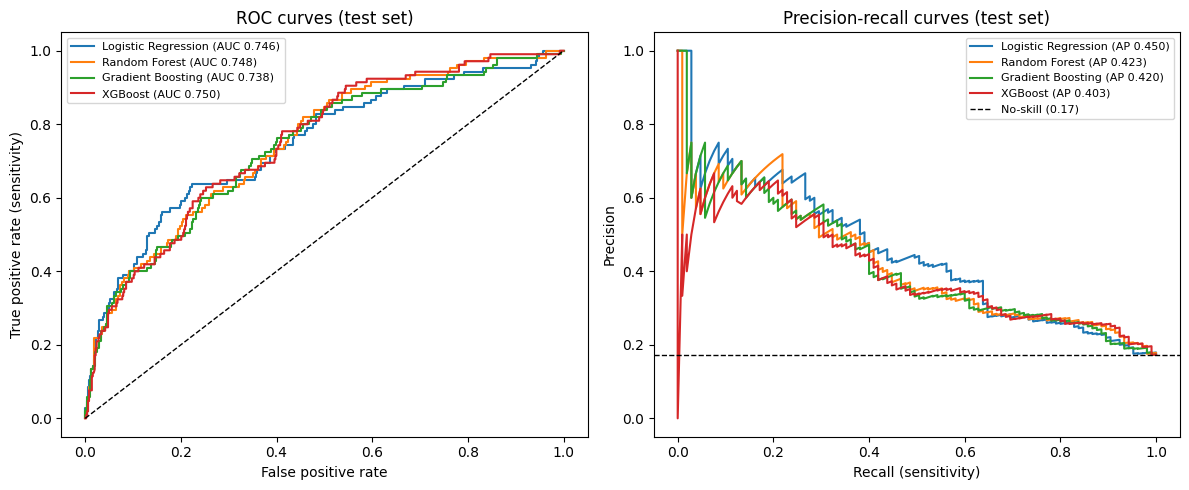

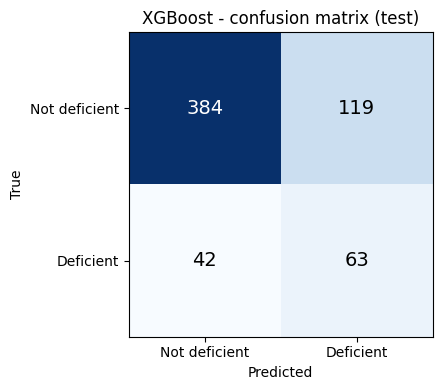


Saved: test_roc_pr_curves.png, test_confusion_matrix.png (left sidebar > Files).


In [69]:
# ============================================================
# STEP 6: FINAL TEST-SET EVALUATION (run once; thresholds fixed in Step 5)
# ============================================================
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)

X_test_B = test_data[set_B_num + set_B_cat]
y_t = np.asarray(y_test)
probs = {name: final_models[name].predict_proba(X_test_B)[:, 1] for name in final_models}
prevalence = y_t.mean()

def threshold_metrics(y, p, t):
    pred = (p >= t).astype(int)
    tp = ((pred == 1) & (y == 1)).sum(); fn = ((pred == 0) & (y == 1)).sum()
    fp = ((pred == 1) & (y == 0)).sum(); tn = ((pred == 0) & (y == 0)).sum()
    sens = tp / (tp + fn); spec = tn / (tn + fp)
    prec = tp / (tp + fp) if (tp + fp) else np.nan
    f1 = 2 * prec * sens / (prec + sens) if (prec + sens) else np.nan
    return {"Sensitivity": sens, "Specificity": spec, "Precision": prec, "F1": f1,
            "Accuracy": (tp + tn) / len(y)}

def all_metrics(y, p, t):
    m = {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p)}
    m.update(threshold_metrics(y, p, t))
    return m

# ---- bootstrap resamples (same resamples for every model -> paired comparisons) ----
rng = np.random.default_rng(42)
B = 2000
boot_idx = [rng.integers(0, len(y_t), len(y_t)) for _ in range(B)]
boot_idx = [i for i in boot_idx if 0 < y_t[i].sum() < len(i)]

def bootstrap(name, t):
    p = probs[name]
    vals = pd.DataFrame([all_metrics(y_t[i], p[i], t) for i in boot_idx])
    return vals

primary_rule = "balanced (Youden)"
rows, boots = [], {}
for name in final_models:
    t = thresholds[name][primary_rule]
    point = all_metrics(y_t, probs[name], t)
    boots[name] = bootstrap(name, t)
    row = {"Model": name, "Threshold": round(t, 3)}
    for k, v in point.items():
        lo, hi = boots[name][k].quantile([0.025, 0.975])
        row[k] = f"{v:.3f} ({lo:.3f}-{hi:.3f})"
    rows.append(row)

pd.set_option("display.width", 300); pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 40)
print(f"TEST SET: n = {len(y_t)}, deficient = {int(y_t.sum())} ({prevalence*100:.1f}%)")
print(f"Primary threshold rule: {primary_rule} (fixed from training data)")
print("Values are: estimate (95% bootstrap CI). PR-AUC of a useless model =", round(prevalence, 3))
print("\nTEST RESULTS - ALL MODELS")
print(pd.DataFrame(rows).to_string(index=False))

# ---- confusion matrices at the primary threshold ----
print("\nCONFUSION MATRICES (rows = true, columns = predicted; [[TN, FP], [FN, TP]])")
for name in final_models:
    t = thresholds[name][primary_rule]
    print(name, " threshold", round(t, 3))
    print(confusion_matrix(y_t, (probs[name] >= t).astype(int)))

# ---- all three threshold rules for the main model ----
main = "XGBoost" if "XGBoost" in final_models else "Gradient Boosting"
print(f"\n{main}: effect of the threshold rule (test set)")
alt_rows = []
for rule, t in thresholds[main].items():
    m = threshold_metrics(y_t, probs[main], t)
    cm = confusion_matrix(y_t, (probs[main] >= t).astype(int)).ravel().tolist()
    alt_rows.append({"Rule": rule, "Threshold": round(t, 3),
                     **{k: round(v, 3) for k, v in m.items()}, "[TN, FP, FN, TP]": cm})
print(pd.DataFrame(alt_rows).to_string(index=False))

# ---- paired bootstrap: main model vs Logistic Regression ----
if main != "Logistic Regression":
    print(f"\nPAIRED BOOTSTRAP: {main} minus Logistic Regression (test set)")
    for metric in ["ROC-AUC", "PR-AUC"]:
        d = boots[main][metric].values - boots["Logistic Regression"][metric].values
        lo, hi = np.quantile(d, [0.025, 0.975])
        print(f"  {metric}: mean difference {d.mean():+.4f}  (95% CI {lo:+.4f} to {hi:+.4f})")
    print("  If the CI includes 0, the two models are not clearly different.")

# ---- plots ----
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name in final_models:
    fpr, tpr, _ = roc_curve(y_t, probs[name])
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_t, probs[name]):.3f})")
    pr, rc, _ = precision_recall_curve(y_t, probs[name])
    ax[1].plot(rc, pr, label=f"{name} (AP {average_precision_score(y_t, probs[name]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate (sensitivity)"); ax[0].set_title("ROC curves (test set)")
ax[1].axhline(prevalence, color="k", ls="--", lw=1, label=f"No-skill ({prevalence:.2f})")
ax[1].set_xlabel("Recall (sensitivity)"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-recall curves (test set)")
for a in ax: a.legend(loc="best", fontsize=8)
plt.tight_layout(); plt.savefig("test_roc_pr_curves.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(4.5, 4))
cm = confusion_matrix(y_t, (probs[main] >= thresholds[main][primary_rule]).astype(int))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, str(v), ha="center", va="center", fontsize=14,
            color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Not deficient", "Deficient"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Not deficient", "Deficient"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"{main} - confusion matrix (test)")
plt.tight_layout(); plt.savefig("test_confusion_matrix.png", dpi=200); plt.show()
print("\nSaved: test_roc_pr_curves.png, test_confusion_matrix.png (left sidebar > Files).")

Explained 608 test women with 22 model inputs (XGBoost).
SHAP values are on the log-odds scale: positive = pushes the prediction toward 'deficient'.


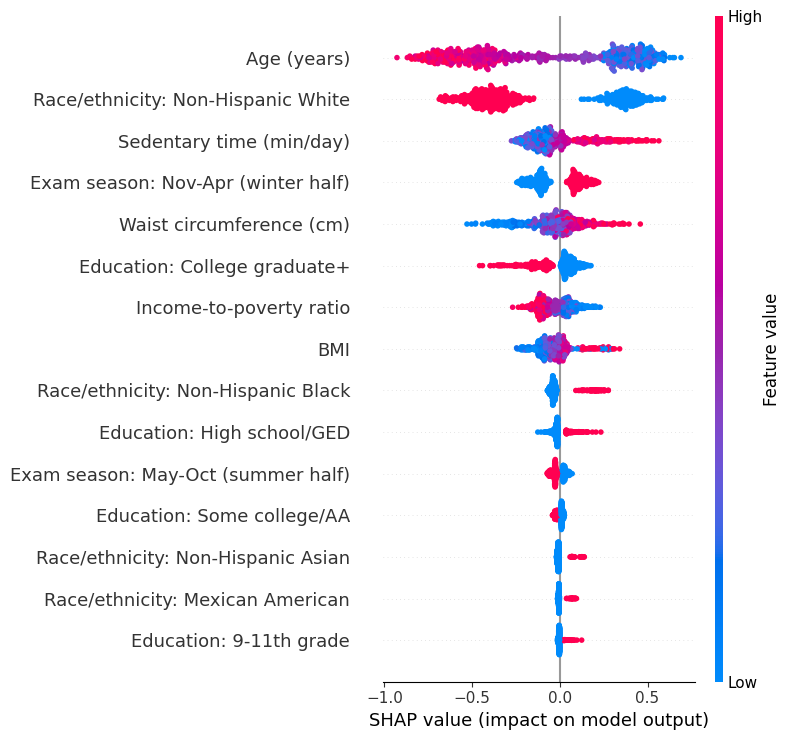

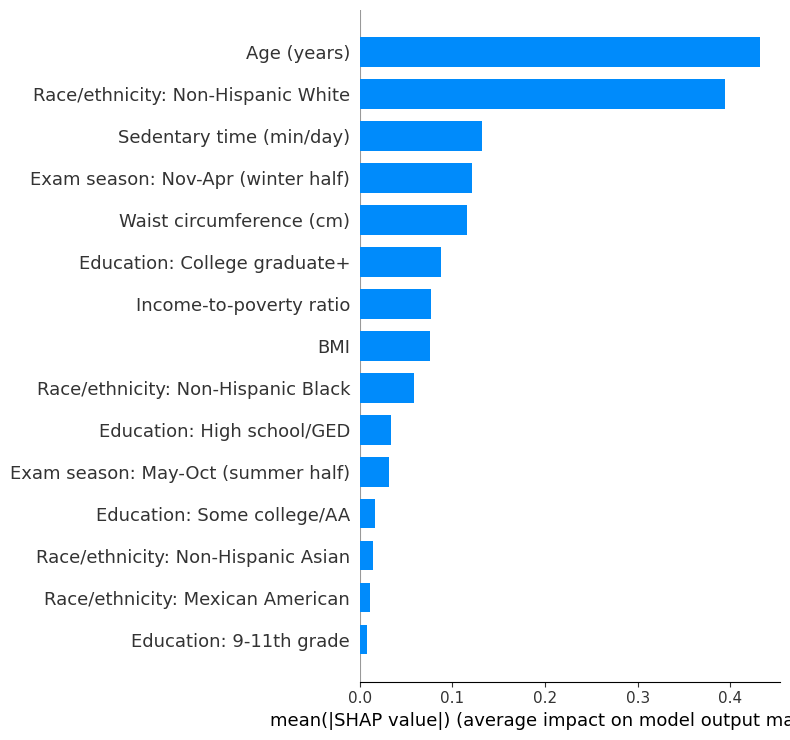


GLOBAL IMPORTANCE BY VARIABLE (mean |SHAP|, log-odds, test women)
                          Mean |SHAP|  Share of total (%)
Race/ethnicity                  0.446           29.100000
Age (years)                     0.432           28.200001
Exam season                     0.153           10.000000
Sedentary time (min/day)        0.132            8.600000
Waist circumference (cm)        0.115            7.500000
Education                       0.101            6.600000
Income-to-poverty ratio         0.078            5.100000
BMI                             0.076            4.900000


<Figure size 640x480 with 0 Axes>

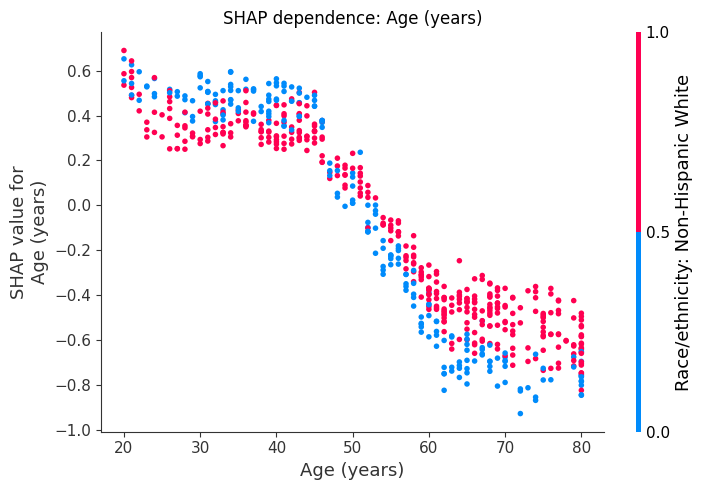

<Figure size 640x480 with 0 Axes>

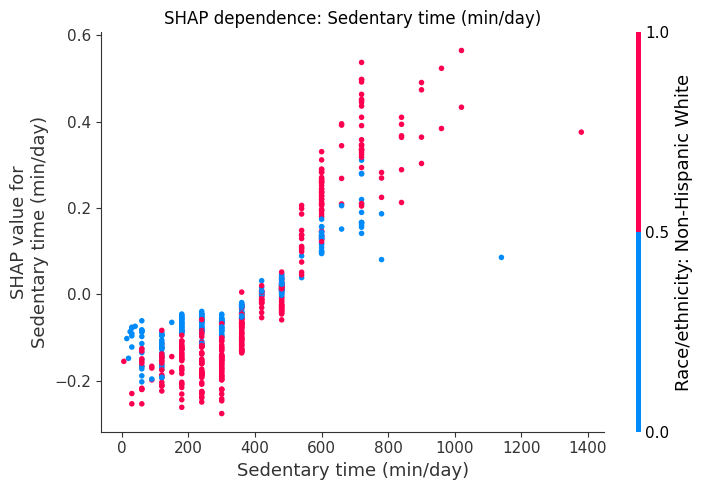

<Figure size 640x480 with 0 Axes>

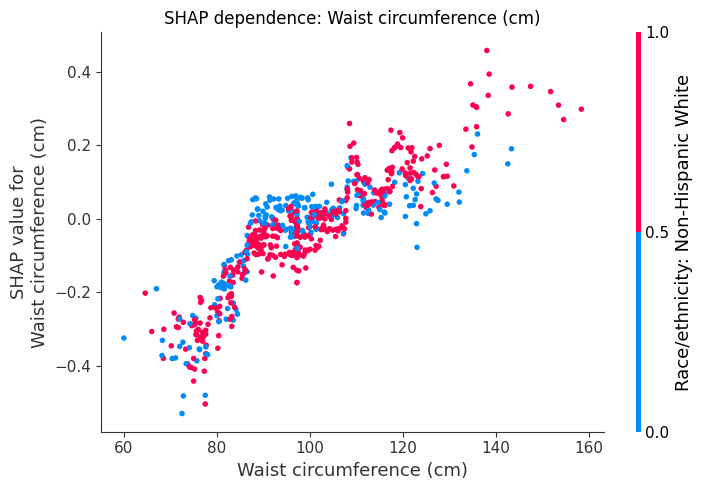


Correctly flagged deficient woman (highest predicted risk among deficient): predicted probability = 0.86, true status = deficient


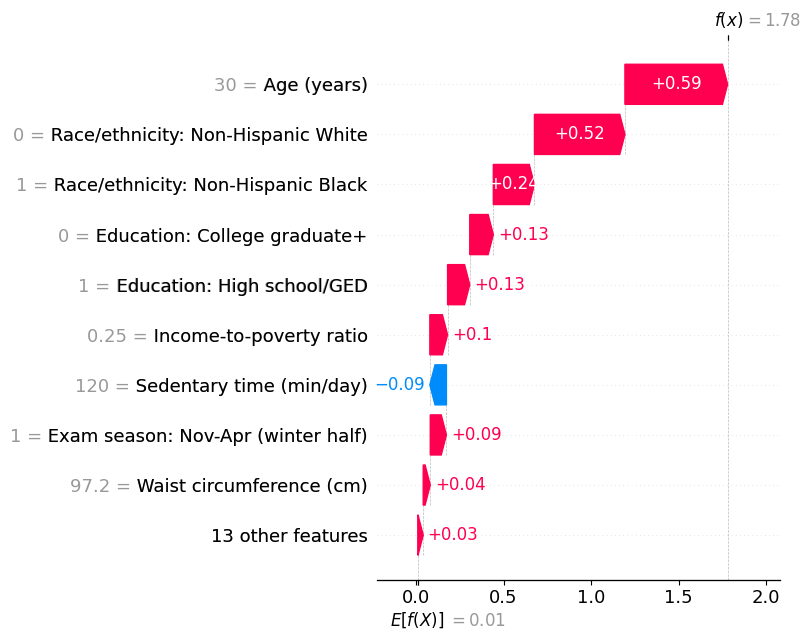


Confidently non-deficient woman (lowest predicted risk among non-deficient): predicted probability = 0.17, true status = not deficient


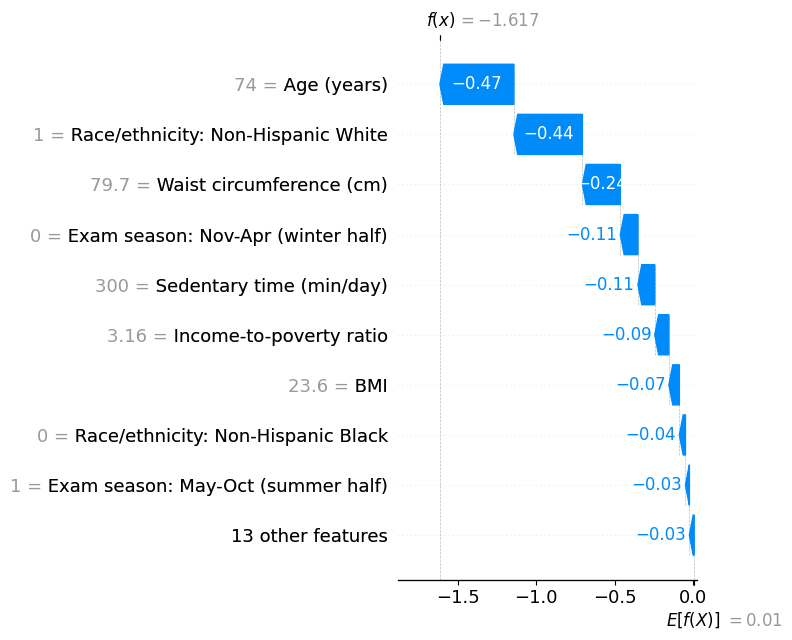


VARIABLE IMPORTANCE RANKS: XGBoost (SHAP) vs Logistic Regression (|coef x value|)
                          XGBoost rank  Logistic Regression rank
Race/ethnicity                       1                         2
Age (years)                          2                         1
Exam season                          3                         4
Sedentary time (min/day)             4                         6
Waist circumference (cm)             5                         5
Education                            6                         3
Income-to-poverty ratio              7                         8
BMI                                  8                         7

Saved plots as .png files (left sidebar > Files).


In [70]:
# ============================================================
# STEP 7: SHAP EXPLAINABILITY for the main model (XGBoost)
# ============================================================
import sys, subprocess, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import shap
except Exception:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)
    importlib.invalidate_caches()
    import shap

main = "XGBoost" if "XGBoost" in final_models else "Gradient Boosting"
pipe = final_models[main]
prep = pipe.named_steps["prep"]
model = pipe.named_steps["model"]
X_explain = test_data[set_B_num + set_B_cat]

# ---------- feature matrix and readable names ----------
Xt = prep.transform(X_explain)
if hasattr(Xt, "toarray"):
    Xt = Xt.toarray()
Xt = np.asarray(Xt, dtype=float)
raw_names = [n.split("__", 1)[-1] for n in prep.get_feature_names_out()]

num_pipe = prep.named_transformers_["num"]
scaler = num_pipe.named_steps["scale"]
n_num_out = len(scaler.mean_)
X_display = Xt.copy()
X_display[:, :n_num_out] = scaler.inverse_transform(Xt[:, :n_num_out])   # back to real units

label_map = {"RIDAGEYR": "Age (years)", "BMXBMI": "BMI", "BMXWAIST": "Waist circumference (cm)",
             "PAD680": "Sedentary time (min/day)", "INDFMPIR": "Income-to-poverty ratio"}
race = {"1": "Mexican American", "2": "Other Hispanic", "3": "Non-Hispanic White",
        "4": "Non-Hispanic Black", "6": "Non-Hispanic Asian", "7": "Other/multiracial", "NA": "missing"}
edu = {"1": "<9th grade", "2": "9-11th grade", "3": "High school/GED",
       "4": "Some college/AA", "5": "College graduate+", "NA": "missing"}
season = {"1": "Nov-Apr (winter half)", "2": "May-Oct (summer half)", "NA": "missing"}

def nice(n):
    if n in label_map: return label_map[n]
    if n.startswith("missingindicator_"):
        return "Missing: " + label_map.get(n.replace("missingindicator_", ""), n.replace("missingindicator_", ""))
    for prefix, title, mp in [("RIDRETH3_cat_", "Race/ethnicity", race),
                              ("DMDEDUC2_cat_", "Education", edu),
                              ("RIDEXMON_cat_", "Exam season", season)]:
        if n.startswith(prefix):
            code = n.replace(prefix, "")
            return f"{title}: {mp.get(code, code)}"
    return n

names = [nice(n) for n in raw_names]
# which original variable does each column belong to? (for grouped importance)
def group_of(n):
    for key, g in [("RIDRETH3_cat", "Race/ethnicity"), ("DMDEDUC2_cat", "Education"),
                   ("RIDEXMON_cat", "Exam season")]:
        if n.startswith(key): return g
    n2 = n.replace("missingindicator_", "")
    return label_map.get(n2, n2)
groups = [group_of(n) for n in raw_names]

# ---------- SHAP values (log-odds scale) ----------
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(Xt)
if isinstance(sv, list):          # some versions return one array per class
    sv = sv[1]
sv = np.asarray(sv)
base_value = float(np.ravel(explainer.expected_value)[-1])
print(f"Explained {len(Xt)} test women with {Xt.shape[1]} model inputs ({main}).")
print("SHAP values are on the log-odds scale: positive = pushes the prediction toward 'deficient'.")

# ---------- 1. Beeswarm + bar plots ----------
try:
    plt.figure()
    shap.summary_plot(sv, X_display, feature_names=names, max_display=15, show=False)
    plt.tight_layout(); plt.savefig("shap_summary_beeswarm.png", dpi=200, bbox_inches="tight"); plt.show()
    plt.figure()
    shap.summary_plot(sv, X_display, feature_names=names, plot_type="bar", max_display=15, show=False)
    plt.tight_layout(); plt.savefig("shap_bar.png", dpi=200, bbox_inches="tight"); plt.show()
except Exception as e:
    print("Summary/bar plot problem:", e)

# ---------- 2. Importance grouped by original variable ----------
sv_df = pd.DataFrame(sv, columns=groups)
grouped = sv_df.T.groupby(level=0).sum().T          # add dummy columns of one variable together
imp = grouped.abs().mean().sort_values(ascending=False)
print("\nGLOBAL IMPORTANCE BY VARIABLE (mean |SHAP|, log-odds, test women)")
print(pd.DataFrame({"Mean |SHAP|": imp.round(3),
                    "Share of total (%)": (imp / imp.sum() * 100).round(1)}).to_string())

# ---------- 3. Dependence plots for the top numeric variables ----------
numeric_labels = [label_map[c] for c in set_B_num]
top_numeric = [v for v in imp.index if v in numeric_labels][:3]
for var in top_numeric:
    try:
        idx = names.index(var)
        plt.figure()
        shap.dependence_plot(idx, sv, X_display, feature_names=names, show=False)
        plt.title(f"SHAP dependence: {var}")
        plt.tight_layout(); plt.savefig(f"shap_dependence_{idx}.png", dpi=200, bbox_inches="tight"); plt.show()
    except Exception as e:
        print("Dependence plot problem for", var, ":", e)

# ---------- 4. Two individual explanations ----------
prob = pipe.predict_proba(X_explain)[:, 1]
y_t = np.asarray(test_data["VitaminD_Deficient"])
cases = []
if (y_t == 1).any():
    cases.append(("Correctly flagged deficient woman (highest predicted risk among deficient)",
                  int(np.argmax(np.where(y_t == 1, prob, -1)))))
if (y_t == 0).any():
    cases.append(("Confidently non-deficient woman (lowest predicted risk among non-deficient)",
                  int(np.argmin(np.where(y_t == 0, prob, 2)))))
for title, i in cases:
    print(f"\n{title}: predicted probability = {prob[i]:.2f}, true status = "
          f"{'deficient' if y_t[i] == 1 else 'not deficient'}")
    try:
        exp = shap.Explanation(values=sv[i], base_values=base_value,
                               data=X_display[i], feature_names=names)
        plt.figure()
        shap.plots.waterfall(exp, max_display=10, show=False)
        plt.tight_layout(); plt.savefig(f"shap_waterfall_{i}.png", dpi=200, bbox_inches="tight"); plt.show()
    except Exception as e:
        print("Waterfall plot problem:", e)

# ---------- 5. Cross-check with Logistic Regression ----------
if "Logistic Regression" in final_models:
    lr = final_models["Logistic Regression"]
    Xt_lr = lr.named_steps["prep"].transform(X_explain)
    if hasattr(Xt_lr, "toarray"): Xt_lr = Xt_lr.toarray()
    coefs = pd.Series(lr.named_steps["model"].coef_[0], index=groups)
    lr_imp = (pd.DataFrame(np.asarray(Xt_lr, dtype=float) * coefs.values, columns=groups)
              .T.groupby(level=0).sum().T.abs().mean().sort_values(ascending=False))
    cmp = pd.DataFrame({"XGBoost rank": imp.rank(ascending=False).astype(int),
                        "Logistic Regression rank": lr_imp.rank(ascending=False).astype(int)})
    print("\nVARIABLE IMPORTANCE RANKS: XGBoost (SHAP) vs Logistic Regression (|coef x value|)")
    print(cmp.sort_values("XGBoost rank").to_string())

print("\nSaved plots as .png files (left sidebar > Files).")

In [71]:
# ============================================================
# STEP 8: SENSITIVITY ANALYSES (none of these change the primary results)
#   A) other Vitamin D cut-offs (30 and 75 nmol/L)
#   B) including the 36 women who were pregnant at the exam
#   C) NHANES phlebotomy survey weights (WTPH2YR)
#   D) model WITHOUT race/ethnicity
# ============================================================
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score

main = "XGBoost" if "XGBoost" in final_models else "Gradient Boosting"
model_names = ["Logistic Regression", main]
feat = set_B_num + set_B_cat
cv_s = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
pd.set_option("display.width", 300); pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 40)

def fresh(name, y_ref):
    """Copy of the final pipeline (same settings, not re-tuned)."""
    p = clone(final_models[name])
    if name == "XGBoost":
        p.named_steps["model"].set_params(scale_pos_weight=(y_ref == 0).sum() / (y_ref == 1).sum())
    return p

def metrics_ci(y, p, w=None, B=1000, seed=42):
    y = np.asarray(y); p = np.asarray(p); w = None if w is None else np.asarray(w)
    roc = roc_auc_score(y, p, sample_weight=w)
    pr = average_precision_score(y, p, sample_weight=w)
    rng = np.random.default_rng(seed); n = len(y); rs, ps = [], []
    for _ in range(B):
        i = rng.integers(0, n, n)
        if y[i].sum() == 0 or y[i].sum() == n:
            continue
        wi = None if w is None else w[i]
        rs.append(roc_auc_score(y[i], p[i], sample_weight=wi))
        ps.append(average_precision_score(y[i], p[i], sample_weight=wi))
    f = lambda v, a: f"{v:.3f} ({np.quantile(a, .025):.3f}-{np.quantile(a, .975):.3f})"
    return f(roc, rs), f(pr, ps)

# ===================== A) other Vitamin D cut-offs =====================
X_tr, X_te = train_data[feat], test_data[feat]
rows = []
for cutoff in [30, 50, 75]:
    y_tr = (train_data["LBXVIDMS"] < cutoff).astype(int).values
    y_te = (test_data["LBXVIDMS"] < cutoff).astype(int).values
    for name in model_names:
        pipe = fresh(name, y_tr)
        r = cross_validate(pipe, X_tr, y_tr, cv=cv_s,
                           scoring={"roc": "roc_auc", "pr": "average_precision"})
        pipe = fresh(name, y_tr).fit(X_tr, y_tr)
        roc_t, pr_t = metrics_ci(y_te, pipe.predict_proba(X_te)[:, 1])
        rows.append({"Cut-off (nmol/L)": cutoff, "Model": name,
                     "Prevalence train": f"{y_tr.mean():.3f}", "Test positives": int(y_te.sum()),
                     "No-skill PR-AUC": f"{y_te.mean():.3f}",
                     "CV ROC-AUC": f"{r['test_roc'].mean():.3f}", "CV PR-AUC": f"{r['test_pr'].mean():.3f}",
                     "Test ROC-AUC (95% CI)": roc_t, "Test PR-AUC (95% CI)": pr_t})
        print("done: cut-off", cutoff, "|", name)
print("\nA) ALTERNATIVE VITAMIN D CUT-OFFS (same settings, no re-tuning)")
print(pd.DataFrame(rows).to_string(index=False))
print("Note: with few positives (small 'Test positives'), the intervals are wide and unreliable.")

# ===================== B) including pregnant women =====================
orig_tr, orig_te = train_test_split(adult_data_clean.index, test_size=0.20, random_state=42,
                                    stratify=adult_data_clean["VitaminD_Deficient"])
preg_idx = set(adult_data_clean.index[adult_data_clean["RIDEXPRG"] == 1])
same = (set(orig_tr) - preg_idx == set(train_data.index)) and (set(orig_te) - preg_idx == set(test_data.index))
print("\nB) Original split reproduced and consistent with the primary split:", same)
if same:
    tr_all, te_all = adult_data_clean.loc[orig_tr], adult_data_clean.loc[orig_te]
    rows = []
    for name in model_names:
        pipe = fresh(name, tr_all["VitaminD_Deficient"].values).fit(tr_all[feat], tr_all["VitaminD_Deficient"])
        roc_t, pr_t = metrics_ci(te_all["VitaminD_Deficient"], pipe.predict_proba(te_all[feat])[:, 1])
        rows.append({"Model": name, "Train n": len(tr_all), "Test n": len(te_all),
                     "Test ROC-AUC (95% CI)": roc_t, "Test PR-AUC (95% CI)": pr_t})
    print("Pregnant women INCLUDED (n = 3,070):")
    print(pd.DataFrame(rows).to_string(index=False))
    print("Compare with the primary results (pregnant excluded) from Step 6.")

# ===================== C) NHANES survey weights =====================
print("\nC) SURVEY WEIGHTS (WTPH2YR = phlebotomy weight, recommended for blood-test analyses)")
if "WTPH2YR" not in train_data.columns:
    print("WTPH2YR is not in the data - skipping C.")
else:
    prim = pd.concat([train_data, test_data])
    w_all = prim["WTPH2YR"]
    print("Missing / zero weights in the primary cohort:", int(w_all.isna().sum()), "/", int((w_all == 0).sum()))
    ok = w_all.notna() & (w_all > 0)
    w_ok, y_ok = w_all[ok], prim.loc[ok, "VitaminD_Deficient"]
    print(f"Unweighted deficiency prevalence : {y_ok.mean():.3f}")
    print(f"Weighted deficiency prevalence   : {np.average(y_ok, weights=w_ok):.3f}  (point estimate for US women 20+ in the sampled population; "
          "no design-based CI here)")
    print(f"Effective sample size (Kish)     : {w_ok.sum() ** 2 / (w_ok ** 2).sum():.0f} of {len(w_ok)}")

    tr_ok = train_data["WTPH2YR"].notna() & (train_data["WTPH2YR"] > 0)
    te_ok = test_data["WTPH2YR"].notna() & (test_data["WTPH2YR"] > 0)
    Xtr_w, ytr_w = train_data.loc[tr_ok, feat], train_data.loc[tr_ok, "VitaminD_Deficient"].values
    Xte_w, yte_w = test_data.loc[te_ok, feat], test_data.loc[te_ok, "VitaminD_Deficient"].values
    w_tr = train_data.loc[tr_ok, "WTPH2YR"].values; w_tr = w_tr / w_tr.mean()
    w_te = test_data.loc[te_ok, "WTPH2YR"].values

    rows = []
    for name in model_names:
        unw = fresh(name, ytr_w).fit(Xtr_w, ytr_w)
        wtd = fresh(name, ytr_w)
        wtd.fit(Xtr_w, ytr_w, model__sample_weight=w_tr)
        for label, mdl, wt in [("Unweighted model, unweighted test", unw, None),
                               ("Unweighted model, weighted test", unw, w_te),
                               ("Weighted model, weighted test", wtd, w_te)]:
            roc_t, pr_t = metrics_ci(yte_w, mdl.predict_proba(Xte_w)[:, 1], w=wt)
            rows.append({"Model": name, "Analysis": label,
                         "ROC-AUC (95% CI)": roc_t, "PR-AUC (95% CI)": pr_t})
    print(pd.DataFrame(rows).to_string(index=False))
    print("Caution: these intervals ignore NHANES strata/clusters, so they are too narrow. "
          "Treat the weighted analysis as a sensitivity check, not as official national estimates.")

# ===================== D) model without race/ethnicity =====================
print("\nD) MODEL WITHOUT RACE/ETHNICITY (same settings, no re-tuning)")
cat_no_race = [c for c in set_B_cat if c != "RIDRETH3_cat"]
y_tr0, y_te0 = train_data["VitaminD_Deficient"].values, test_data["VitaminD_Deficient"].values
rows = []
for name in model_names:
    mdl = clone(final_models[name].named_steps["model"])
    pipe = build_pipeline(set_B_num, cat_no_race, mdl)
    r = cross_validate(pipe, train_data[set_B_num + cat_no_race], y_tr0, cv=cv_s,
                       scoring={"roc": "roc_auc", "pr": "average_precision"})
    pipe.fit(train_data[set_B_num + cat_no_race], y_tr0)
    roc_t, pr_t = metrics_ci(y_te0, pipe.predict_proba(test_data[set_B_num + cat_no_race])[:, 1])
    rows.append({"Model": name, "CV ROC-AUC": f"{r['test_roc'].mean():.3f}",
                 "CV PR-AUC": f"{r['test_pr'].mean():.3f}",
                 "Test ROC-AUC (95% CI)": roc_t, "Test PR-AUC (95% CI)": pr_t})
print(pd.DataFrame(rows).to_string(index=False))
print("Compare with set B WITH race/ethnicity: CV ROC-AUC about 0.77 and PR-AUC about 0.45-0.46 (Steps 4-5); "
      "test results in Step 6.")

done: cut-off 30 | Logistic Regression
done: cut-off 30 | XGBoost
done: cut-off 50 | Logistic Regression
done: cut-off 50 | XGBoost
done: cut-off 75 | Logistic Regression
done: cut-off 75 | XGBoost

A) ALTERNATIVE VITAMIN D CUT-OFFS (same settings, no re-tuning)
 Cut-off (nmol/L)               Model Prevalence train  Test positives No-skill PR-AUC CV ROC-AUC CV PR-AUC Test ROC-AUC (95% CI) Test PR-AUC (95% CI)
               30 Logistic Regression            0.046              32           0.053      0.813     0.336   0.788 (0.695-0.873)  0.241 (0.141-0.412)
               30             XGBoost            0.046              32           0.053      0.793     0.276   0.770 (0.675-0.853)  0.183 (0.105-0.319)
               50 Logistic Regression            0.171             105           0.173      0.773     0.453   0.746 (0.690-0.797)  0.450 (0.358-0.554)
               50             XGBoost            0.171             105           0.173      0.776     0.465   0.750 (0.697-0.795)  0.